# Main-text figures

Run cells in order from the repository root. Data figures read bundled numerical inputs and appear inline. Figs. 1 and 9 display exports of the editable schematic in `results/GINE_concise_editable.pptx`. Outputs are written under `results/reproduced/`; typography and layout may differ from the final manuscript artwork.


## Fig. 1 — architecture and representation schematic


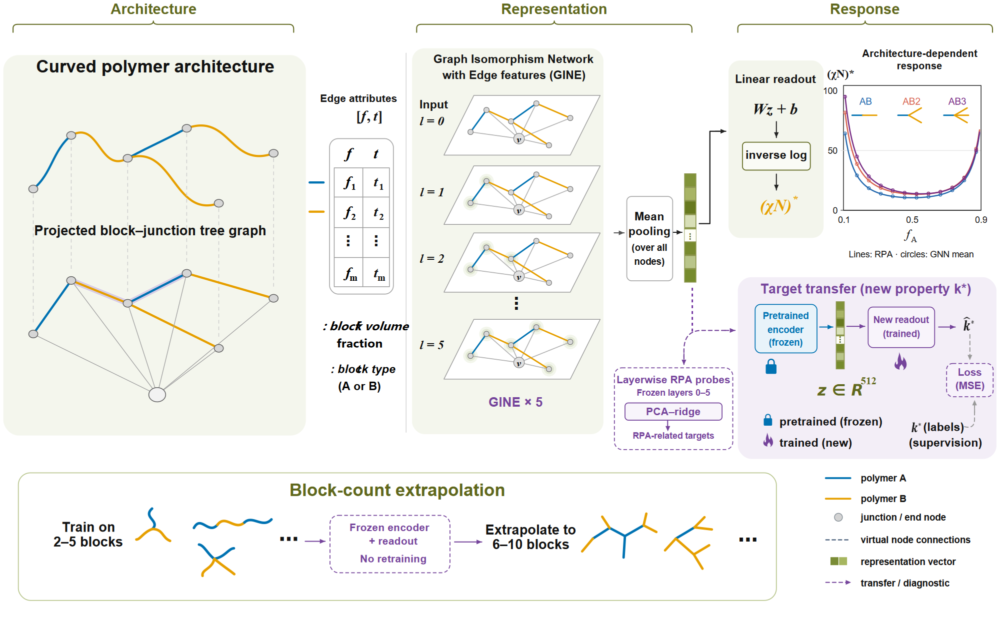

In [1]:
from pathlib import Path
from IPython.display import display, Image
CODE = next(p for base in (Path.cwd(), *Path.cwd().parents)
            for p in (base, base / "sourcecode/code")
            if (p / "results/GINE_concise_editable.pptx").is_file())
# Figure 1 is authored in the editable PPTX; display its verified export.
display(Image(filename=str(CODE / "results/figures/gine_ppt_vector/figure1_architecture_representation.png"), width=1100))


## Fig. 2 — architecture and response distributions


Code: D:\2026\paper\TAPD\sourcecode\code
Python: D:\2026\paper\TAPD\.venv\Scripts\python.exe


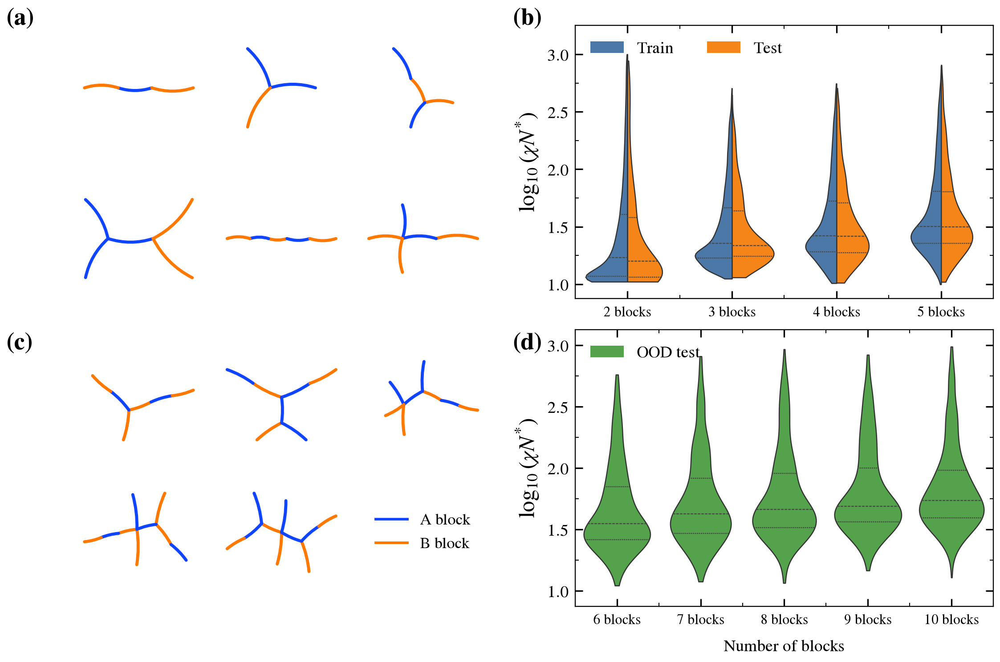

D:\2026\paper\TAPD\sourcecode\code\results\reproduced\figure_acbd\figure_acbd_four_panel


In [2]:
def _draw_main_fig2():
    from pathlib import Path
    import sys, subprocess, json
    import numpy as np
    import pandas as pd
    from IPython.display import display, Image

    cwd = Path.cwd().resolve()
    CODE = next(p for base in (cwd, *cwd.parents) for p in (base, base / "sourcecode/code")
                if (p / "README.md").is_file() and (p / "notebooks").is_dir())
    OUTPUT = CODE / "results/reproduced/figure_acbd"
    print("Code:", CODE)
    print("Python:", sys.executable)

    # The figure scripts consume only the copied local architecture and response tables.
    LOCAL_INPUTS = {
        "training": CODE / "data/figure_acbd/responses/training_100k_response_data.csv",
        "validation": CODE / "data/figure_acbd/responses/validation_seed43_2k_response_data.csv",
        "ood": CODE / "data/figure_acbd/responses/ood_6to10blocks_response_manifest.csv",
    }
    if not all(path.is_file() for path in LOCAL_INPUTS.values()):
        raise FileNotFoundError(LOCAL_INPUTS)
    if not list((CODE / "data/figure_acbd/architecture").rglob("*.yml")):
        raise FileNotFoundError("No local architecture inputs found")

    # Main Fig. 2: draw all four panels from local YAML and CSV inputs on one canvas.
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    sys.path.insert(0, str(CODE / "src/plotting"))
    from paper_style import configure_paper_style, save_dual

    _panel_sources = [('scripts\\figure_acbd\\redraw_ac_topologies_mpltex.py', '#!/usr/bin/env python3\n"""Redraw the Figure 2 a/c topology panels in the TAPD paper style."""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\nimport math\nimport sys\n\nimport matplotlib.pyplot as plt\nfrom matplotlib.lines import Line2D\nimport networkx as nx\nimport numpy as np\nimport yaml\n\n\nROOT = Path(__file__).resolve().parents[2]\nTRAIN_DATA = ROOT / "data/figure_acbd/architecture/train"\nOOD_DATA = ROOT / "data/figure_acbd/architecture/ood"\nOUT_STEM = ROOT / "results/figures/figure_acbd/ac_representative_topologies"\n\n\nfrom paper_style import (  # noqa: E402\n    TOPOLOGY_COLORS,\n    configure_paper_style,\n    draw_topology,\n    save_dual,\n)\n\n\n# Preserve the six training topologies used in the existing a panel.\nTRAIN_SAMPLES = [\n    "3blocks_sample_27020",\n    "3blocks_sample_01839",\n    "4blocks_sample_19583",\n    "5blocks_sample_12582",\n    "5blocks_sample_00369",\n    "5blocks_sample_04529",\n]\n\n# Preserve the five representative OOD samples selected for the existing c panel.\nOOD_SAMPLES = [\n    "6blocks_sample_00137",\n    "7blocks_sample_00203",\n    "8blocks_sample_00050",\n    "9blocks_sample_00005",\n    "10blocks_sample_00286",\n]\n\n\ndef load_blocks(directory: Path, stem: str) -> list[dict]:\n    with (directory / f"{stem}.yml").open(encoding="utf-8") as handle:\n        return yaml.safe_load(handle)["system"]["components"][0]["blocks"]\n\n\ndef graph_layout(blocks: list[dict]) -> dict[str, tuple[float, float]]:\n    graph = nx.Graph()\n    graph.add_edges_from(tuple(block["ends"]) for block in blocks)\n    raw = nx.kamada_kawai_layout(graph, weight=None)\n    nodes = sorted(raw)\n    points = np.asarray([raw[node] for node in nodes], dtype=float)\n    points -= points.mean(axis=0)\n    _, _, vh = np.linalg.svd(points, full_matrices=False)\n    points = points @ vh.T\n    if np.ptp(points[:, 0]) < np.ptp(points[:, 1]):\n        points = points[:, ::-1]\n    points[:, 0] /= max(np.max(np.abs(points[:, 0])), 1e-9)\n    points[:, 1] /= max(np.max(np.abs(points[:, 1])), 1e-9)\n    points[:, 1] *= 0.72\n    return {node: tuple(points[index]) for index, node in enumerate(nodes)}\n\n\ndef reference_a_layout(blocks: list[dict]) -> dict[str, tuple[float, float]]:\n    """Reproduce the deterministic tree layout used by the original a images."""\n    adjacency: dict[str, list[str]] = {}\n    for block in blocks:\n        n1, n2 = block["ends"]\n        adjacency.setdefault(n1, []).append(n2)\n        adjacency.setdefault(n2, []).append(n1)\n    root = max(sorted(adjacency), key=lambda node: len(adjacency[node]))\n    positions: dict[str, tuple[float, float]] = {root: (0.0, 0.0)}\n\n    def walk(node: str, parent: str | None, start: float, end: float, depth: int) -> None:\n        children = [child for child in adjacency[node] if child != parent]\n        if not children:\n            return\n        if len(children) == 1:\n            angles = [(start + end) / 2.0]\n        else:\n            step = (end - start) / max(1, len(children) - 1)\n            angles = [start + index * step for index in range(len(children))]\n        radius = 1.05 + 0.18 * depth\n        x0, y0 = positions[node]\n        for child, angle in zip(sorted(children), angles):\n            positions[child] = (x0 + radius * math.cos(angle),\n                                y0 + radius * math.sin(angle))\n            spread = max(math.pi / 5.0,\n                         (end - start) / max(2.4, len(children) + 1.0))\n            walk(child, node, angle - spread, angle + spread, depth + 1)\n\n    degree = len(adjacency[root])\n    initial_angles = [0.0] if degree <= 1 else [\n        2.0 * math.pi * index / degree for index in range(degree)\n    ]\n    for neighbor, angle in zip(sorted(adjacency[root]), initial_angles):\n        positions[neighbor] = (math.cos(angle), math.sin(angle))\n        walk(neighbor, root, angle - math.pi / 4.0, angle + math.pi / 4.0, 1)\n\n    points = np.asarray(list(positions.values()), dtype=float)\n    center = 0.5 * (points.min(axis=0) + points.max(axis=0))\n    points -= center\n    scale = max(np.max(np.abs(points[:, 0])), np.max(np.abs(points[:, 1])) / 0.72, 1e-9)\n    points /= scale\n    return {node: tuple(points[index]) for index, node in enumerate(positions)}\n\n\ndef draw_chain(\n    ax,\n    blocks: list[dict],\n    positions: dict[str, tuple[float, float]],\n    *,\n    reference_a: bool = False,\n) -> None:\n    # Small alternating bends reproduce the smooth, hand-drawn reference while\n    # retaining the exact graph connectivity and A/B identity of every block.\n    edges = []\n    for index, block in enumerate(blocks):\n        curvature = 0.16 if reference_a else 0.075 * (-1.0 if index % 2 else 1.0)\n        edges.append((*block["ends"], str(block["segment"]), curvature))\n\n    collection_start = len(ax.collections)\n    patch_start = len(ax.patches)\n    draw_topology(ax, positions, edges)\n\n    # The supplied reference is line-only: retain rounded paths, omit all nodes,\n    # and use the requested 5.8 pt line rather than the helper\'s standalone scale.\n    for patch in ax.patches[patch_start:]:\n        patch.set_linewidth(3.3)\n    for collection in list(ax.collections[collection_start:]):\n        collection.remove()\n\n    ax.set(xlim=(-1.18, 1.18), ylim=(-0.88, 0.88), aspect="equal")\n    ax.axis("off")\n\n\ndef add_grid_axes(fig, panel_bottom: float) -> list:\n    panel_left, panel_width, panel_height = 0.10, 0.865, 0.427\n    gap_x, gap_y = 0.018, 0.035\n    cell_width = (panel_width - 2 * gap_x) / 3\n    cell_height = (panel_height - gap_y) / 2\n    axes = []\n    for index in range(6):\n        row, col = divmod(index, 3)\n        left = panel_left + col * (cell_width + gap_x)\n        bottom = panel_bottom + (1 - row) * (cell_height + gap_y)\n        axes.append(fig.add_axes([left, bottom, cell_width, cell_height]))\n    return axes\n\n\n'), ('scripts\\figure_acbd\\redraw_bd_violin_seed43_mpltex.py', '#!/usr/bin/env python3\n"""Redraw only panels b/d; panels a/c remain untouched in the master artwork."""\n\nfrom __future__ import annotations\n\nimport os\nimport sys\nfrom pathlib import Path\n\n\n\nROOT = Path(__file__).resolve().parents[2]\n\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport seaborn as sns\nimport yaml\nfrom matplotlib.patches import Patch\nfrom matplotlib.ticker import MultipleLocator\n\nfrom paper_style import configure_paper_style, save_dual, style_distribution_axis\n\n\nTRAIN_TABLE = ROOT / "data/figure_acbd/responses/training_100k_response_data.csv"\nTEST_TABLE = ROOT / "data/figure_acbd/responses/validation_seed43_2k_response_data.csv"\nOOD_MANIFEST = ROOT / "data/figure_acbd/responses/ood_6to10blocks_response_manifest.csv"\nOUT_STEM = ROOT / "results/figures/figure_acbd/bd_response_distributions"\n\n# Preserve the reference palette exactly.\nTRAIN_COLOR, TEST_COLOR, OOD_COLOR = "#4C78A8", "#F58518", "#54A24B"\n\n\ndef load_test() -> pd.DataFrame:\n    frame = pd.read_csv(TEST_TABLE, usecols=["n_blocks", "log10_chiN_star"])\n    frame["dataset"] = "Test"\n    if len(frame) != 2000:\n        raise RuntimeError(f"Expected 2,000 seed43 independent test samples, found {len(frame)}.")\n    return frame\n\n\ndef draw(\n    ax,\n    frame: pd.DataFrame,\n    blocks: list[int],\n    palette: dict[str, str],\n    split: bool,\n    ylim: tuple[float, float],\n) -> None:\n    labels = [f"{n} blocks" for n in blocks]\n    frame = frame.copy()\n    frame["block_label"] = pd.Categorical(\n        frame["n_blocks"].map(lambda n: f"{n} blocks"), categories=labels, ordered=True\n    )\n    sns.violinplot(\n        data=frame, x="block_label", y="log10_chiN_star", hue="dataset",\n        order=labels, hue_order=list(palette), palette=palette, split=split,\n        inner="quartile", cut=0, density_norm="area", common_norm=False,\n        linewidth=2.0, saturation=1, ax=ax,\n    )\n    ax.set(xlabel="", ylabel=r"$\\log_{10}(\\chi N^{*})$", ylim=ylim)\n    ax.set_yticks(np.arange(1.0, 3.01, 0.5))\n    ax.yaxis.set_minor_locator(MultipleLocator(0.25))\n    ax.set_ylabel(r"$\\log_{10}(\\chi N^{*})$", fontsize=24, labelpad=8)\n    # Matplotlib expresses box aspect as height / width: 2 / 3 gives 3:2.\n    ax.set_box_aspect(2.0 / 3.0)\n    style_distribution_axis(ax)\n    # Keep the frame and internal quartile lines at the 2.8 pt reference\n    # stroke, while using the requested 2.0 pt violin outlines.\n    for spine in ax.spines.values():\n        spine.set_linewidth(1.1)\n    for collection in ax.collections:\n        collection.set_linewidth(1.2)\n        collection.set_edgecolor("#333333")\n    for line in ax.lines:\n        line.set_linewidth(1.1)\n    ax.tick_params(which="major", labelsize=18, pad=7)\n    ax.grid(False)\n    if ax.get_legend() is not None:\n        ax.get_legend().remove()\n\n\ndef save_single_panel(\n    frame: pd.DataFrame,\n    blocks: list[int],\n    palette: dict[str, str],\n    split: bool,\n    ylim: tuple[float, float],\n    legend_handles: list[Patch],\n    stem: Path,\n) -> None:\n    """Export a standalone panel for lossless a--d composition."""\n    fig, ax = plt.subplots(figsize=(12.0, 8.1), facecolor="white")\n    draw(ax, frame, blocks, palette, split=split, ylim=ylim)\n    ax.legend(handles=legend_handles, loc="upper left", frameon=False, fontsize=29,\n              ncol=len(legend_handles), handlelength=1.8, handleheight=1.0,\n              columnspacing=1.0)\n    fig.subplots_adjust(left=0.10, right=0.965, bottom=0.13, top=0.96)\n    fig.text(0.5325, 0.045, "Number of blocks", ha="center", va="center", fontsize=34)\n    save_dual(fig, stem, tight=False)\n    plt.close(fig)\n\n\n')]
    _namespaces = []
    for relative_path, source in _panel_sources:
        namespace = {"__file__": str(CODE / relative_path), "__name__": "figure2_data_panel"}
        exec(compile(source, relative_path, "exec"), namespace)
        _namespaces.append(namespace)
    topology, distribution = _namespaces
    configure_paper_style()
    fig = plt.figure(figsize=(15.2, 10.2), facecolor="white")
    grid = fig.add_gridspec(2, 2, left=.065, right=.973, bottom=.09, top=.96,
                            wspace=.22, hspace=.24, width_ratios=[1, 1.1])
    for row in range(2):
        subgrid = grid[row, 0].subgridspec(2, 3, wspace=.04, hspace=.10)
        samples = topology["TRAIN_SAMPLES"] if row == 0 else topology["OOD_SAMPLES"]
        directory = topology["TRAIN_DATA"] if row == 0 else topology["OOD_DATA"]
        for j in range(6):
            ax = fig.add_subplot(subgrid[j // 3, j % 3])
            box = ax.get_position()
            dx = (.003, .012, .020)[j % 3]
            dy = ((.008, -.010) if row == 0 else (.030, .040))[j // 3]
            ax.set_position([box.x0 + dx, box.y0 + dy, box.width, box.height])
            if j < len(samples):
                blocks = topology["load_blocks"](directory, samples[j])
                positions = (topology["reference_a_layout"](blocks) if row == 0
                             else topology["graph_layout"](blocks))
                topology["draw_chain"](ax, blocks, positions, reference_a=(row == 0))
            else:
                ax.axis("off")
                ax.legend(handles=[Line2D([], [], color="#1045FF", label="A block"),
                                   Line2D([], [], color="#FF7900", label="B block")],
                          loc="center", frameon=False, fontsize=17)
    train = pd.read_csv(distribution["TRAIN_TABLE"], usecols=["n_blocks", "log10_chiN_star"])
    train["dataset"] = "Train"
    test = distribution["load_test"]()
    ood = pd.read_csv(distribution["OOD_MANIFEST"],
                      usecols=["block_count", "log10_chiN_star"]).rename(columns={"block_count": "n_blocks"})
    ood["dataset"] = "OOD test"
    for row, frame, blocks, palette in [
        (0, pd.concat([train, test]), [2, 3, 4, 5],
         {"Train": distribution["TRAIN_COLOR"], "Test": distribution["TEST_COLOR"]}),
        (1, ood, [6, 7, 8, 9, 10], {"OOD test": distribution["OOD_COLOR"]}),
    ]:
        ax = fig.add_subplot(grid[row, 1])
        distribution["draw"](ax, frame, blocks, palette, row == 0,
                             (.875, 3.25 if row == 0 else 3.125))
        ax.set_box_aspect(None)
        ax.legend(handles=[Patch(facecolor=color, label=label) for label, color in palette.items()],
                  loc="upper left", ncol=len(palette), fontsize=18, frameon=False)
        if row == 1:
            ax.set_xlabel("Number of blocks", fontsize=18, labelpad=12)
        box = ax.get_position()
        left, bottom, width, height = ((.561, .566, .412, .401) if row == 0
                                        else (.561, .114, .412, .406))
        ax.set_position([left, bottom, width, height])
        ax.tick_params(axis="x", labelsize=15, pad=8)
    for label, x, y in [("a", .001, .995), ("b", .500, .995),
                        ("c", .001, .518), ("d", .500, .518)]:
        fig.text(x, y, f"({label})", fontsize=26, fontweight="bold", va="top")
    output = CODE / "results/reproduced/figure_acbd/figure_acbd_four_panel"
    output.parent.mkdir(parents=True, exist_ok=True)
    save_dual(fig, output, tight=False)
    fig.savefig(output.with_suffix(".pdf"), facecolor="white")
    display(fig)
    plt.close(fig)
    print(output)

_draw_main_fig2()


## Fig. 3 — independent test-set comparison


                 MAPE                RMSE                 MAE                  R2         
                 mean       std      mean       std      mean       std      mean      std
model                                                                                     
gnn          0.423767  0.090469  1.080466  0.331984  0.323900  0.097677  0.999837  0.00010
mlp          2.211654  0.106048  5.394152  0.517105  1.670467  0.100666  0.996188  0.00074
transformer  0.367908  0.034343  1.014471  0.113817  0.275748  0.028330  0.999865  0.00003


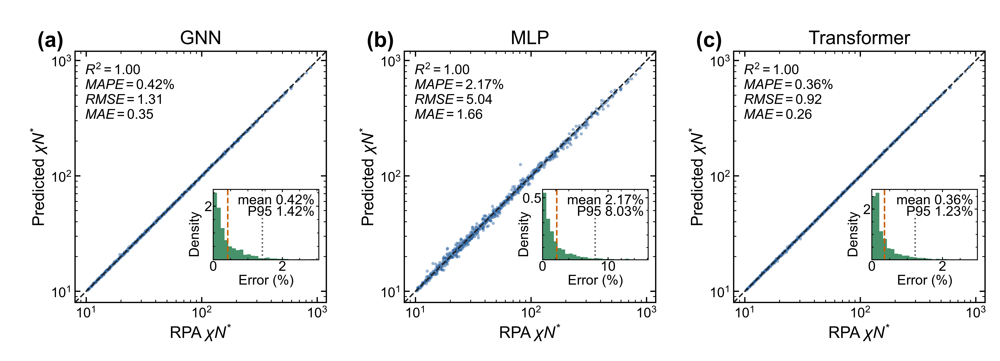

In [3]:
def _draw_main_fig3():
    from pathlib import Path
    import json, sys
    import numpy as np
    import pandas as pd
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/plotting/paper_style.py').is_file()) / 'src/plotting'))
    from paper_style import COLORS, configure_paper_style, style_axis, save_dual
    configure_paper_style()
    # SI exports use native mathtext and typography at the final insertion width.
    from si_style import configure_si_math, save_dual
    configure_si_math()
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
    from IPython.display import display, Image
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'checkpoints/gnn').is_dir())
    DATA = ROOT / 'results/source_data/final_evaluation'
    OUT = ROOT / 'results/reproduced/seed43_final_evaluation'
    OUT.mkdir(parents=True, exist_ok=True)
    SEEDS = tuple(range(202601,202606))
    LOSS_COLORS = ('blue','red','green','purple','amber')
    def publish(fig, stem, *, tight=False):
        save_dual(fig, stem, tight=tight)
        fig.savefig(stem.with_suffix('.pdf'), dpi=600, facecolor='white')
        display(Image(filename=str(stem.with_suffix('.png')), width=850))
        plt.close(fig)

    predictions = {}
    rows = []
    for model in ['gnn','mlp','transformer']:
        for seed in SEEDS:
            folder = DATA / model
            suffix = '.csv' if model == 'transformer' else '.npz'
            path = next(p for p in folder.rglob('*') if 'prediction' in p.name and str(seed) in p.name and p.suffix == suffix and ('seed43' in str(p) or 'final_test_seed43' in str(p)))
            if suffix == '.npz':
                with np.load(path, allow_pickle=True) as d:
                    true, pred = 10**d['y_true_log'], 10**d['y_pred_log']
                    ids = d['sample_id'].astype(str) if 'sample_id' in d else None
            else:
                frame = pd.read_csv(path)
                true, pred, ids = frame['true'].to_numpy(), frame.pred.to_numpy(), frame.base_name.to_numpy()
            assert len(true)==2000 and np.all(np.isfinite(pred)) and np.all(pred>0)
            predictions[model,seed] = (true,pred,ids)
            error = pred-true
            rows.append(dict(model=model,seed=seed,MAPE=float((np.abs(error)/true*100).mean()),RMSE=float(np.sqrt(np.mean(error**2))),MAE=float(np.abs(error).mean()),R2=float(1-np.sum(error**2)/np.sum((true-true.mean())**2))))
    reference = predictions['mlp',202601]
    for true,pred,ids in predictions.values():
        np.testing.assert_allclose(true,reference[0],rtol=1e-6)
        if ids is not None: np.testing.assert_array_equal(ids,reference[2])
    metrics = pd.DataFrame(rows)
    summary = metrics.groupby('model')[['MAPE','RMSE','MAE','R2']].agg(['mean','std'])
    for model,mean,sd in [('mlp',2.2117,.1060),('gnn',.4238,.0905),('transformer',.3679,.0343)]:
        np.testing.assert_allclose(summary.loc[model, 'MAPE'].to_numpy(),[mean,sd],atol=5e-5,rtol=0)
    metrics.to_csv(DATA/'seed43_per_seed_metrics.csv',index=False)
    summary.to_csv(DATA/'seed43_summary.csv')
    print(summary.to_string())

    MODEL_ORDER = [("gnn", "GNN"),
                   ("mlp", "MLP"),
                   ("transformer", "Transformer")]
    REPRESENTATIVE_SEED = 202604

    with plt.rc_context({
            "font.family": "Arial",
            "mathtext.fontset": "custom",
            "mathtext.rm": "Arial",
            "mathtext.it": "Arial:italic",
            "mathtext.bf": "Arial:bold",
            "font.size": 15.2, "axes.labelsize": 18,
            "xtick.labelsize": 15.2, "ytick.labelsize": 15.2,
            "axes.titlesize": 21}):
        fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.6), facecolor="white")
        for panel, (model, label) in enumerate(MODEL_ORDER):
            ax = axes[panel]
            true, pred, _ = predictions[model, REPRESENTATIVE_SEED]
            result = metrics[(metrics.model == model) &
                             (metrics.seed == REPRESENTATIVE_SEED)].iloc[0]
            rel = np.abs(pred - true) / np.clip(np.abs(true), 1e-12, None) * 100
            mean_error = float(rel.mean())
            p95_error = float(np.percentile(rel, 95))
            upper = float(np.percentile(rel, 99.5))

            ax.scatter(true, pred, s=13, color=COLORS["parity_blue"], alpha=0.42,
                       edgecolors="white", linewidths=0.25, rasterized=True, zorder=2)
            ax.plot([8, 1200], [8, 1200], "--", color=COLORS["black"], lw=1.6, zorder=3)
            ax.set(xscale="log", yscale="log", xlim=(8, 1200), ylim=(8, 1200),
                   xlabel=r"RPA $\chi N^{*}$", ylabel=r"Predicted $\chi N^{*}$")
            ax.set_box_aspect(1)
            ax.set_title(label, pad=8)
            ax.text(0.04, 0.96,
                    "\n".join((rf"$R^2={result.R2:.2f}$",
                                 rf"$MAPE={result.MAPE:.2f}\%$",
                                 rf"$RMSE={result.RMSE:.2f}$",
                                 rf"$MAE={result.MAE:.2f}$")),
                    transform=ax.transAxes, ha="left", va="top", fontsize=15.2)
            style_axis(ax)
            ax.tick_params(axis="both", which="major", labelsize=15.2, length=6, width=1.4)
            ax.tick_params(axis="both", which="minor", length=3, width=0.9)
            for spine in ax.spines.values():
                spine.set_linewidth(1.4)

            inset = ax.inset_axes([0.55, 0.17, 0.42, 0.28])
            inset.hist(rel, bins=np.linspace(0, upper, 28), density=True,
                       color=COLORS["density_green"], alpha=0.82, edgecolor="none")
            inset.axvline(mean_error, color=COLORS["mean_orange"], ls="--", lw=1.7)
            inset.axvline(p95_error, color="0.35", ls=":", lw=1.7)
            inset.set(xlim=(0, upper * 1.04))
            inset.set_xlabel("Error (%)", fontsize=15.2, labelpad=1.2)
            density_label = inset.set_ylabel("Density", fontsize=15.2, labelpad=2.2)
            inset.yaxis.set_label_coords(-0.11, 0.36)
            density_label.set_bbox(dict(facecolor="white", edgecolor="none", pad=0.35))
            style_axis(inset)
            # Keep the x-axis origin label and suppress the duplicate y-axis zero at the same corner.
            inset.yaxis.set_major_formatter(
                FuncFormatter(lambda value, _pos: "" if np.isclose(value, 0.0) else f"{value:g}")
            )
            inset.tick_params(axis="both", which="major", labelsize=15.2, length=3, width=1.0, pad=1.2)
            inset.tick_params(axis="both", which="minor", length=2, width=0.8)
            for tick_label in inset.get_yticklabels():
                tick_label.set_bbox(dict(facecolor="white", edgecolor="none", pad=0.15))
            for spine in inset.spines.values():
                spine.set_linewidth(1.0)
            inset.text(0.96, 0.94, f"mean {mean_error:.2f}%\nP95 {p95_error:.2f}%",
                       transform=inset.transAxes, ha="right", va="top", fontsize=15.2,
                       linespacing=0.9,
                       bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.82, "pad": 0.4})

            ax.text(-0.15, 1.08, f"({chr(97 + panel)})", transform=ax.transAxes,
                    fontsize=24, fontweight="bold", ha="left", va="top")

        fig.subplots_adjust(left=0.075, right=0.985, bottom=0.16, top=0.86, wspace=0.31)
        publish(fig, OUT / "in_domain_model_comparison", tight=False)

_draw_main_fig3()


## Fig. 4 — block-count extrapolation


In [4]:
def _draw_main_fig4():
    from pathlib import Path
    import json
    from IPython.display import display, Image
    import numpy as np
    import pandas as pd
    import sys
    STYLE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/plotting/paper_style.py').is_file()) / 'src/plotting'
    sys.path.insert(0, str(STYLE_DIR))
    from paper_style import COLORS, configure_paper_style, style_axis, style_distribution_axis, save_dual
    configure_paper_style()
    # Native mathtext and SI typography at the final insertion width.
    from si_style import configure_si_math, save_dual
    configure_si_math()
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter

    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'results/source_data/block_extrapolation').is_dir())
    DATA = ROOT / 'results/source_data/block_extrapolation'
    OUT = ROOT / 'results/reproduced/block_extrapolation'
    OUT.mkdir(parents=True, exist_ok=True)
    SEEDS = range(202601, 202606)
    MODELS = ['GNN', 'MLP', 'Transformer']
    METRICS = ['MAPE', 'RMSE', 'MAE', 'R2']


    def metrics(frame):
        true, pred = frame.y_true.to_numpy(float), frame.y_pred.to_numpy(float)
        if not (np.isfinite(true).all() and np.isfinite(pred).all() and (true > 0).all()):
            raise ValueError('Metrics require finite predictions and positive reference values')
        residual = pred - true
        return {'MAPE': np.mean(np.abs(residual) / true) * 100,
                'RMSE': np.sqrt(np.mean(residual**2)), 'MAE': np.mean(np.abs(residual)),
                'R2': 1 - np.sum(residual**2) / np.sum((true - true.mean())**2)}


    def publish(fig, output_stem, *, tight=True):
        save_dual(fig, output_stem, tight=tight)
        fig.savefig(Path(output_stem).with_suffix('.pdf'), facecolor='white', **({'bbox_inches':'tight', 'pad_inches':.03} if tight else {}))
        display(Image(filename=str(Path(output_stem).with_suffix('.png')), width=1100))
        plt.close(fig)

    def save(fig, name, *, tight=True):
        for ax in fig.axes:
            if ax.get_label() == '<colorbar>':
                continue
            style_axis(ax)
            if ax.get_title(): ax.title.set_fontsize(32)
            ax.margins(x=.08)
            for child in ax.child_axes: style_axis(child)
        publish(fig, OUT/name, tight=tight)



    # Confirm the metric helper on a fixed pair.
    check = metrics(pd.DataFrame({'y_true': [1., 2.], 'y_pred': [2., 2.]}))
    assert check['MAPE'] == 50 and check['MAE'] == .5 and check['R2'] == -1

    frames, overall_rows, block_rows = [], [], []
    reference = None
    for model in MODELS:
        for seed in SEEDS:
            if model == 'GNN':
                folder = DATA / f'gnn/seed{seed}'
                frame = pd.read_csv(folder / 'transfer_predictions.csv')
                reference_metrics = json.loads((folder / 'transfer_metrics.json').read_text())
            elif model == 'MLP':
                # Local NPZ stores object-string sample identifiers.
                with np.load(DATA / f'mlp/seed{seed}_ood_predictions.npz', allow_pickle=True) as data:
                    frame = pd.DataFrame({'sample_name': data['sample_id'].astype(str),
                                          'block_count': data['block_count'],
                                          'y_true': data['y_true'], 'y_pred': data['y_pred']})
                reference_metrics = pd.read_csv(DATA / 'mlp/per_seed_overall_metrics.csv').set_index('seed').loc[seed].to_dict()
                reference_metrics['MAPE'] = reference_metrics.get('MAPE_percent', reference_metrics.get('MAPE'))
            else:
                stem = f'seed{seed}_transfer_6to10blocks'
                frame = pd.read_csv(DATA / f'transformer/{stem}_predictions.csv')
                reference_metrics = json.loads((DATA / f'transformer/{stem}.json').read_text())
            frame = frame.sort_values('sample_name').reset_index(drop=True)
            assert len(frame) == 2500 and frame.sample_name.is_unique
            assert frame.block_count.value_counts().sort_index().to_dict() == dict.fromkeys(range(6, 11), 500)
            if reference is None:
                reference = frame[['sample_name', 'block_count', 'y_true']].copy()
            assert frame.sample_name.equals(reference.sample_name)
            assert frame.block_count.equals(reference.block_count)
            np.testing.assert_allclose(frame.y_true, reference.y_true, rtol=2e-6, atol=1e-5)
            calculated = metrics(frame)
            for key in METRICS:
                np.testing.assert_allclose(calculated[key], reference_metrics[key], rtol=3e-6, atol=3e-5,
                                           err_msg=f'{model}, seed {seed}, {key}')
            overall_rows.append({'model': model, 'seed': seed, **calculated})
            for count, group in frame.groupby('block_count'):
                block_rows.append({'model': model, 'seed': seed, 'block_count': count, **metrics(group)})
            frames.append(frame[['sample_name', 'block_count', 'y_true', 'y_pred']].assign(model=model, seed=seed))
    predictions = pd.concat(frames, ignore_index=True)
    overall = pd.DataFrame(overall_rows)
    per_block = pd.DataFrame(block_rows)
    summary = overall.groupby('model')[METRICS].agg(['mean', 'std']).reindex(MODELS)
    block_summary = per_block.groupby(['model', 'block_count'])[METRICS].agg(['mean', 'std'])
    overall.to_csv(DATA / 'all_models_per_seed_metrics.csv', index=False)
    per_block.to_csv(DATA / 'all_models_per_seed_per_block_metrics.csv', index=False)
    summary.to_csv(DATA / 'all_models_summary.csv')
    block_summary.to_csv(DATA / 'all_models_per_block_summary.csv')
    print(summary.round(5).to_string())

    model_colors = {'GNN': COLORS['blue'], 'MLP': COLORS['orange'], 'Transformer': COLORS['teal']}
    model_markers = {'GNN': 'o', 'MLP': 's', 'Transformer': '^'}
    model_offsets = {'GNN': -0.11, 'MLP': 0, 'Transformer': 0.11}
    blocks = np.arange(6, 11)

    REPRESENTATIVE_SEED = 202604
    BLOCK_COLORS = {
        6: COLORS["blue"], 7: COLORS["green"], 8: COLORS["purple"],
        9: COLORS["red"], 10: COLORS["amber"],
    }
    PARITY_LIMITS = {"GNN": (8, 1200), "MLP": (8, 8000), "Transformer": (8, 1200)}

    with plt.rc_context({"font.family": "Arial",
                         "mathtext.fontset": "custom",
                         "mathtext.rm": "Arial",
                         "mathtext.it": "Arial:italic",
                         "mathtext.bf": "Arial:bold",
                         "font.size": 12, "axes.labelsize": 15,
                         "xtick.labelsize": 12, "ytick.labelsize": 12,
                         "axes.titlesize": 16, "legend.fontsize": 13}):
        fig = plt.figure(figsize=(15.5, 11.2), facecolor="white")
        outer = fig.add_gridspec(2, 1, height_ratios=(0.92, 1.0), hspace=0.34)
        top = outer[0].subgridspec(1, 2, wspace=0.27)
        bottom = outer[1].subgridspec(1, 3, wspace=0.31)
        top_axes = [fig.add_subplot(top[0, i]) for i in range(2)]
        parity_axes = [fig.add_subplot(bottom[0, i]) for i in range(3)]

        for model in MODELS:
            part = block_summary.loc[model].loc[blocks]
            x = blocks + model_offsets[model]
            for ax, metric in zip(top_axes, ("MAPE", "R2")):
                ax.errorbar(
                    x, part[(metric, "mean")], yerr=part[(metric, "std")],
                    color=model_colors[model], marker=model_markers[model],
                    markersize=6.5, markerfacecolor="white", markeredgewidth=1.4,
                    linewidth=2.0, elinewidth=1.05, capsize=3.2, capthick=1.05,
                    label=model, zorder=3,
                )

        for ax in top_axes:
            ax.set(xlabel="Number of blocks", xlim=(5.65, 10.35), xticks=blocks)
            style_axis(ax)
            ax.tick_params(axis="both", which="major", labelsize=17, length=8, width=1.8)
            ax.tick_params(axis="both", which="minor", length=4, width=1.2)
            ax.xaxis.label.set_fontsize(21)
            ax.yaxis.label.set_fontsize(21)
            for spine in ax.spines.values():
                spine.set_linewidth(1.8)

        top_axes[0].set(yscale="log", ylim=(2.5, 410), ylabel="MAPE (%)")
        top_axes[0].yaxis.set_major_locator(FixedLocator([3, 10, 30, 100, 300]))
        top_axes[0].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
        top_axes[0].yaxis.set_minor_formatter(NullFormatter())
        top_axes[1].set(ylim=(-10.5, 1.25), yticks=[-10, -8, -6, -4, -2, 0, 1], ylabel=r"$R^2$")
        top_axes[1].axhline(0, color="0.45", linewidth=1.0, linestyle="--", zorder=1)

        zoom = top_axes[1].inset_axes([0.08, 0.10, 0.46, 0.46])
        for model in MODELS:
            part = block_summary.loc[model].loc[blocks]
            zoom.errorbar(
                blocks + model_offsets[model], part[("R2", "mean")], yerr=part[("R2", "std")],
                color=model_colors[model], marker=model_markers[model],
                markersize=3.8, markerfacecolor="white", markeredgewidth=0.9,
                linewidth=1.2, elinewidth=0.7, capsize=2.0, capthick=0.7, zorder=3,
            )
        zoom.set(xlim=(5.75, 10.25), ylim=(-0.55, 1.05), xticks=[6, 8, 10],
                 yticks=[-0.5, 0, 0.5, 1.0])
        zoom.axhline(0, color="0.45", linewidth=0.7, linestyle="--", zorder=1)
        style_axis(zoom)
        zoom.set_title("Expanded view", fontsize=12, pad=3)
        zoom.tick_params(axis="both", which="major", labelsize=9, length=3.5, width=0.9)
        zoom.tick_params(axis="both", which="minor", length=1.8, width=0.7)
        for spine in zoom.spines.values():
            spine.set_linewidth(1.0)

        for ax, panel in zip(top_axes, "ab"):
            ax.text(-0.10, 1.08, f"({panel})", transform=ax.transAxes,
                    fontsize=18, fontweight="bold", ha="left", va="top")

        model_handles, model_labels = top_axes[0].get_legend_handles_labels()
        fig.legend(model_handles, model_labels, loc="upper center", ncol=3,
                   frameon=False, bbox_to_anchor=(0.5, 0.995),
                   columnspacing=1.8, handlelength=2.0, fontsize=17)

        for ax, model, panel in zip(parity_axes, MODELS, "cde"):
            frame = predictions[(predictions.model == model) &
                                (predictions.seed == REPRESENTATIVE_SEED)]
            frame = frame.iloc[np.random.default_rng(REPRESENTATIVE_SEED).permutation(len(frame))]
            colors = [BLOCK_COLORS[int(count)] for count in frame.block_count]
            ax.scatter(frame.y_true, frame.y_pred, s=13, c=colors, alpha=0.42,
                       edgecolors="white", linewidths=0.25, rasterized=True, zorder=2)
            low, high = PARITY_LIMITS[model]
            ax.plot([low, high], [low, high], "--", color=COLORS["black"], lw=1.6, zorder=3)
            ax.set(xscale="log", yscale="log", xlim=(low, high), ylim=(low, high),
                   xlabel=r"RPA $\chi N^{*}$", ylabel=r"Predicted $\chi N^{*}$")
            ax.set_box_aspect(1)
            ax.xaxis.label.set_fontsize(18)
            ax.yaxis.label.set_fontsize(18)
            ax.set_title(model, fontsize=21, pad=8)
            result = overall[(overall.model == model) &
                             (overall.seed == REPRESENTATIVE_SEED)].iloc[0]
            ax.text(0.04, 0.96,
                    "\n".join((rf"$R^2={result.R2:.2f}$",
                                 rf"$MAPE={result.MAPE:.2f}\%$",
                                 rf"$RMSE={result.RMSE:.2f}$",
                                 rf"$MAE={result.MAE:.2f}$")),
                    transform=ax.transAxes, ha="left", va="top", fontsize=15.2)
            style_axis(ax)
            ax.tick_params(axis="both", which="major", labelsize=15.2, length=6, width=1.4)
            ax.tick_params(axis="both", which="minor", length=3, width=0.9)
            for spine in ax.spines.values():
                spine.set_linewidth(1.4)
            ax.text(-0.15, 1.08, f"({panel})", transform=ax.transAxes,
                    fontsize=24, fontweight="bold", ha="left", va="top")

        block_handles = [Line2D([0], [0], marker="o", linestyle="none", markersize=6,
                                markerfacecolor=BLOCK_COLORS[count], markeredgecolor="white",
                                markeredgewidth=0.25, alpha=0.8, label=f"{count} blocks")
                         for count in sorted(BLOCK_COLORS)]
        parity_axes[0].legend(handles=block_handles, loc="lower right",
                              bbox_to_anchor=(1.0, 0.045), ncol=1, frameon=False,
                              fontsize=10, handletextpad=0.45, labelspacing=0.35,
                              borderaxespad=0.55, markerscale=0.9)
        fig.subplots_adjust(left=0.075, right=0.985, bottom=0.065, top=0.91)
        publish(fig, OUT / "Fig4_block_extrapolation", tight=False)

_draw_main_fig4()


                 MAPE                 RMSE                 MAE                 R2         
                 mean       std       mean       std      mean       std     mean      std
model                                                                                     
GNN          13.32991   4.74169   50.09096  13.22471  17.97584   6.21503  0.79900  0.11474
MLP          86.25710  15.25827  195.43060  46.02000  65.11586   7.53869 -2.02659  1.40055
Transformer  88.02206  61.46024  121.15920  31.59289  64.98313  25.12214 -0.17445  0.66795


## Fig. 5 — mechanistic interpretation


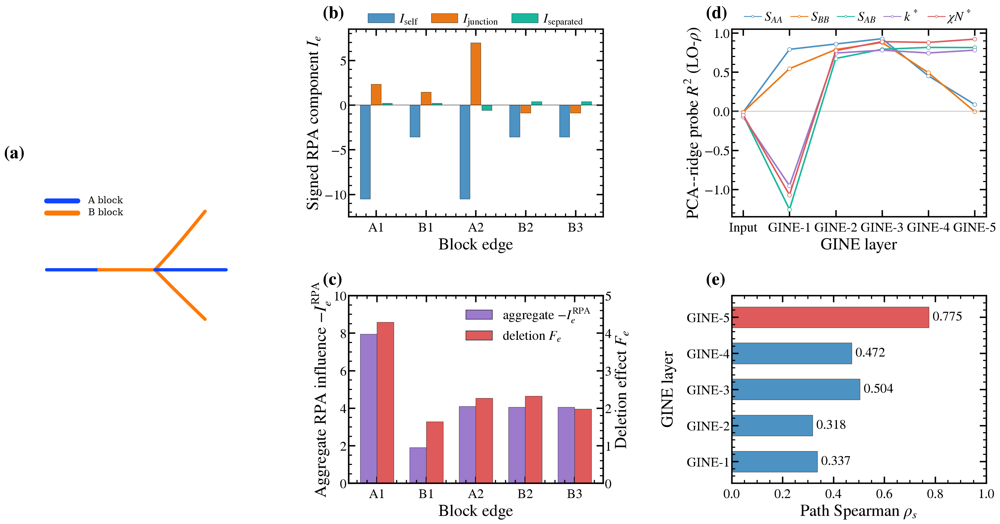

D:\2026\paper\TAPD\sourcecode\code\results\reproduced\mechanistic_interpretability\fig5_mechanistic_interpretability


In [5]:
def _draw_main_fig5():
    # Main Fig. 5: numerical panels come from CSV/JSON; the topology is vector artwork
    # drawn here, so this cell never opens an existing panel image.
    from pathlib import Path
    import sys, types
    import numpy as np
    import pandas as pd
    from IPython.display import Image, display
    CODE = next(p for base in (Path.cwd(), *Path.cwd().parents) for p in (base, base / "sourcecode/code")
                if (p / "data/mechanistic_interpretability/rpa").is_dir())
    sys.path.insert(0, str(CODE / "src/plotting"))
    from paper_style import COLORS, configure_paper_style, save_dual, style_axis
    import matplotlib.pyplot as plt
    from matplotlib.path import Path as MplPath
    from matplotlib.patches import PathPatch

    _panel_source = '#!/usr/bin/env python3\n"""Draw the four-panel mechanistic-interpretability figure directly with Matplotlib."""\nfrom __future__ import annotations\n\nimport json\nfrom pathlib import Path\n\nimport matplotlib\n\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom matplotlib.patches import Patch\n\n\nHERE = Path(__file__).resolve().parent\nRESULTS = HERE / "results"\nHISTORY_RESULTS = HERE.parent / "figure" / "results_legal_growth_histories"\nOUTPUT = HERE.parent / "figure" / "abtab2_interpretability_statistics"\nEDGE_ORDER = ["A1", "B1", "A2", "B2", "B3"]\nCOLORS = {\n    "blue": "#4C93C3",\n    "orange": "#E9780D",\n    "teal": "#1CB39E",\n    "purple": "#9B75CC",\n    "red": "#E15759",\n    "ink": "#222222",\n}\n\n\ndef configure_style() -> None:\n    plt.rcParams.update({\n        "font.family": "sans-serif",\n        "font.sans-serif": ["Arial", "DejaVu Sans"],\n        "mathtext.fontset": "dejavusans",\n        "font.size": 8.5,\n        "axes.labelsize": 9.5,\n        "legend.fontsize": 8,\n        "xtick.labelsize": 8.5,\n        "ytick.labelsize": 8.5,\n        "axes.linewidth": 1.0,\n        "xtick.major.width": 1.0,\n        "ytick.major.width": 1.0,\n        "xtick.major.size": 4,\n        "ytick.major.size": 4,\n        "legend.frameon": False,\n        "savefig.dpi": 600,\n    })\n\n\ndef representative_rows() -> tuple[pd.DataFrame, pd.DataFrame]:\n    edges = pd.read_csv(RESULTS / "abtab2_rpa_edge_influence.csv")\n    deletion = pd.read_csv(RESULTS / "abtab2_gnnexplainer_edge_summary.csv")\n    edges = edges[np.isclose(edges.f_A, 0.5) & np.isclose(edges.rho, 1.0)].copy()\n    deletion = deletion[np.isclose(deletion.f_A, 0.5) & np.isclose(deletion.rho, 1.0)].copy()\n    for frame in (edges, deletion):\n        frame["edge"] = pd.Categorical(frame.edge, EDGE_ORDER, ordered=True)\n        frame.sort_values("edge", inplace=True)\n    assert edges.edge.astype(str).tolist() == EDGE_ORDER\n    assert deletion.edge.astype(str).tolist() == EDGE_ORDER\n    return edges, deletion\n\n\ndef style_axis(ax: plt.Axes) -> None:\n    ax.tick_params(direction="in", top=True, right=True)\n    for spine in ax.spines.values():\n        spine.set_color(COLORS["ink"])\n\n\ndef panel_a(ax: plt.Axes, edges: pd.DataFrame) -> None:\n    x = np.arange(len(edges))\n    width = 0.22\n    specs = [\n        ("I_self", r"$I_{\\mathrm{self}}$", COLORS["blue"]),\n        ("I_junction", r"$I_{\\mathrm{junction}}$", COLORS["orange"]),\n        ("I_separated", r"$I_{\\mathrm{separated}}$", COLORS["teal"]),\n    ]\n    for offset, (column, label, color) in zip((-width, 0, width), specs):\n        ax.bar(x + offset, edges[column], width * 0.92, color=color,\n               edgecolor=COLORS["ink"], linewidth=0.55, label=label)\n    ax.axhline(0, color=COLORS["ink"], linewidth=0.8)\n    ax.set(xticks=x, xticklabels=EDGE_ORDER, xlabel="Block edge",\n           ylabel=r"Signed RPA component $I_e$", ylim=(-12.5, 8.5))\n    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=3,\n              columnspacing=1.0, handletextpad=0.4)\n    style_axis(ax)\n\n\ndef panel_b(ax: plt.Axes, edges: pd.DataFrame, deletion: pd.DataFrame) -> None:\n    x = np.arange(len(edges))\n    width = 0.34\n    ax.bar(x - width / 2, -edges.I_total, width, color=COLORS["purple"],\n           edgecolor=COLORS["ink"], linewidth=0.55)\n    ax.set(xticks=x, xticklabels=EDGE_ORDER, xlabel="Block edge",\n           ylabel=r"Aggregate RPA influence $-I_e^{\\mathrm{RPA}}$", ylim=(0, 10))\n    style_axis(ax)\n\n    ax2 = ax.twinx()\n    ax2.bar(x + width / 2, deletion.deletion_mean, width, color=COLORS["red"],\n            edgecolor=COLORS["ink"], linewidth=0.55)\n    ax2.set_ylabel(r"Deletion effect $F_e$")\n    ax2.set_ylim(0, 5)\n    style_axis(ax2)\n    handles = [\n        Patch(facecolor=COLORS["purple"], edgecolor=COLORS["ink"],\n              label=r"aggregate $-I_e^{\\mathrm{RPA}}$"),\n        Patch(facecolor=COLORS["red"], edgecolor=COLORS["ink"],\n              label=r"deletion $F_e$"),\n    ]\n    ax.legend(handles=handles, loc="upper right")\n\n\ndef panel_c(ax: plt.Axes) -> None:\n    probe = pd.read_csv(RESULTS / "abtab2_layerwise_probe.csv")\n    specs = [\n        ("S_AA", r"$S_{AA}$", COLORS["blue"]),\n        ("S_BB", r"$S_{BB}$", COLORS["orange"]),\n        ("S_AB", r"$S_{AB}$", COLORS["teal"]),\n        ("q_star", r"$k^*$", COLORS["purple"]),\n        ("chiN_star", r"$\\chi N^*$", COLORS["red"]),\n    ]\n    for concept, label, color in specs:\n        rows = probe[probe.concept.eq(concept)].sort_values("layer")\n        ax.plot(rows.layer, rows.R2_grouped_by_rho, "o-", color=color,\n                markerfacecolor="white", markeredgewidth=0.9, linewidth=1.6,\n                markersize=4.2, label=label)\n    ax.axhline(0, color="#888888", linewidth=0.7)\n    ax.set_xlabel("GINE layer")\n    ax.set_ylabel(r"PCA--ridge probe $R^2$ (LO-$\\rho$)")\n    ax.set_xticks(range(6), ["Input", "GINE-1", "GINE-2", "GINE-3", "GINE-4", "GINE-5"])\n    ax.set_ylim(min(-1.35, probe.R2_grouped_by_rho.min() - 0.05), 1.05)\n    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.17), ncol=5,\n              columnspacing=0.55, handlelength=1.3, handletextpad=0.25)\n    style_axis(ax)\n\n\ndef panel_d(ax: plt.Axes) -> None:\n    summary = json.loads((HISTORY_RESULTS / "summary.json").read_text(encoding="utf-8"))\n    rows = [row for row in summary["summary"] if row["layer"] > 0]\n    assert len(rows) == 5 and {row["n_pairs"] for row in rows} == {16065}\n    values = np.array([row["spearman_mean_embedding_vs_RPA_path"] for row in rows])\n    labels = [f"GINE-{row[\'layer\']}" for row in rows]\n    y = np.arange(len(rows))\n    colors = [COLORS["blue"]] * 4 + [COLORS["red"]]\n    bars = ax.barh(y, values, height=0.58, color=colors,\n                   edgecolor=COLORS["ink"], linewidth=0.55)\n    ax.set(yticks=y, yticklabels=labels, xlabel=r"Path Spearman $\\rho_s$",\n           ylabel="GINE layer", xlim=(0, 1), ylim=(-0.6, 4.6))\n    for bar, value in zip(bars, values):\n        ax.text(value + 0.015, bar.get_y() + bar.get_height() / 2,\n                f"{value:.3f}", va="center", fontsize=8.5)\n    style_axis(ax)\n\n\n'
    panels = types.ModuleType("mechanistic_numeric_panels")
    panels.__file__ = str(CODE / "scripts/mechanistic_interpretability/plot_interpretability_statistics.py")
    exec(compile(_panel_source, panels.__file__, "exec"), panels.__dict__)
    panels.RESULTS = CODE / "data/mechanistic_interpretability/rpa"
    panels.HISTORY_RESULTS = CODE / "data/mechanistic_interpretability/legal_histories"
    panels.COLORS = {**COLORS, "ink": COLORS["black"]}
    panels.style_axis = style_axis

    def draw_topology(ax):
        """Editable A/B block diagram, redrawn as paths rather than loaded artwork."""
        ax.set(xlim=(0, 1), ylim=(0, 1))
        ax.axis("off")
        blue, orange = "#1045FF", "#FF7900"
        # Match the source artwork's preserved aspect inside the tall left panel.
        y = lambda value: .47 + .33 * (value - .40)
        ax.plot([.08, .23], [y(.86), y(.86)], color=blue, lw=9, solid_capstyle="round")
        ax.plot([.08, .23], [y(.78), y(.78)], color=orange, lw=9, solid_capstyle="round")
        ax.text(.28, y(.86), "A block", va="center", fontsize=17, fontfamily="serif")
        ax.text(.28, y(.78), "B block", va="center", fontsize=17, fontfamily="serif")
        ax.plot([.08, .33], [y(.40), y(.40)], color=blue, lw=6, solid_capstyle="round")
        ax.plot([.33, .60], [y(.40), y(.40)], color=orange, lw=6, solid_capstyle="round")
        ax.plot([.60, .94], [y(.40), y(.40)], color=blue, lw=6, solid_capstyle="round")
        for end in ((.84, .79), (.84, .07)):
            path = MplPath([(.60, y(.40)), (.69, y(.53 if end[1] > .4 else .27)), (end[0], y(end[1]))],
                           [MplPath.MOVETO, MplPath.CURVE3, MplPath.CURVE3])
            ax.add_patch(PathPatch(path, fill=False, color=orange, lw=6, capstyle="round"))

    configure_paper_style()
    edges, deletion = panels.representative_rows()
    fig = plt.figure(figsize=(26, 13.5), facecolor="white")
    grid = fig.add_gridspec(2, 3, width_ratios=(.82, 1, 1),
                            left=.055, right=.965, bottom=.09, top=.94, wspace=.46, hspace=.42)
    axes = {"a": fig.add_subplot(grid[:, 0]), "b": fig.add_subplot(grid[0, 1]),
            "c": fig.add_subplot(grid[1, 1]), "d": fig.add_subplot(grid[0, 2]),
            "e": fig.add_subplot(grid[1, 2])}
    draw_topology(axes["a"])
    panels.panel_a(axes["b"], edges)
    panels.panel_b(axes["c"], edges, deletion)
    panels.panel_c(axes["d"])
    panels.panel_d(axes["e"])
    for key in "bcde":
        axes[key].tick_params(axis="x", which="major", pad=9)
    axes["d"].xaxis.set_minor_locator(panels.matplotlib.ticker.NullLocator())
    axes["d"].tick_params(axis="x", which="minor", bottom=False, top=False)
    for key in "de":
        box = axes[key].get_position()
        axes[key].set_position([box.x0 + .018, box.y0, box.width, box.height])
    axes["e"].yaxis.labelpad = 18
    for line in axes["d"].lines:
        if line.get_marker() not in (None, "None", ""):
            line.set_linewidth(2.8)
            line.set_markersize(7)
            line.set_markeredgewidth(1.0)
    for text in axes["e"].texts:
        text.set_fontsize(24)
    for label, ax in axes.items():
        box = ax.get_position()
        fig.text(box.x0 - .025, .69 if label == "a" else box.y1 + .012, f"({label})",
                 fontsize=32, fontweight="bold", va="bottom", ha="left")
    output = CODE / "results/reproduced/mechanistic_interpretability/fig5_mechanistic_interpretability"
    output.parent.mkdir(parents=True, exist_ok=True)
    save_dual(fig, output, tight=False)
    fig.savefig(output.with_suffix(".pdf"), facecolor="white")
    display(fig)
    plt.close(fig)
    print(output)

_draw_main_fig5()


## Fig. 6 — cross-target transfer


In [6]:
def _draw_main_fig6():
    from pathlib import Path
    import sys

    import numpy as np
    import pandas as pd
    from IPython.display import Image, display


    def find_code_root():
        for base in (Path.cwd(), *Path.cwd().parents):
            for candidate in (base, base / "sourcecode" / "code"):
                if (candidate / "results/source_data/kstar_transfer").is_dir():
                    return candidate.resolve()
        raise FileNotFoundError("Could not locate sourcecode/code")


    CODE_ROOT = find_code_root()
    DATA_ROOT = CODE_ROOT / "results/source_data/kstar_transfer/main_evidence_20260913"
    LIMITED_ROOT = CODE_ROOT / "results/source_data/kstar_transfer/limited_n100"
    LOSS_ROOT = CODE_ROOT / "results/source_data/kstar_transfer/gnn/finalmodel/transfer"
    FIGURE_ROOT = CODE_ROOT / "results/reproduced/kstar_transfer"
    FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

    STYLE_ROOT = CODE_ROOT / "src/plotting"
    sys.path.insert(0, str(STYLE_ROOT))
    from paper_style import COLORS, configure_paper_style, save_dual, style_axis

    configure_paper_style()
    # Native mathtext and SI typography at the final insertion width.
    from si_style import configure_si_math, save_dual
    configure_si_math()
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from matplotlib.ticker import FixedLocator, FuncFormatter, LogFormatterMathtext, LogLocator, NullFormatter

    CODE_ROOT

    SEEDS = (202601, 202602, 202603, 202604, 202605)
    SIZES = (100, 250, 500, 1000, 2000)
    METHODS = ("frozen_encoder", "frozen_embedding_mlp", "finetune_encoder", "two_stage", "scratch")
    LABELS = {
        "frozen_encoder": "Frozen + linear",
        "frozen_embedding_mlp": "Frozen + MLP",
        "finetune_encoder": "End-to-end fine-tuning",
        "two_stage": "Two-stage transfer",
        "scratch": "Scratch",
    }
    SHORT_LABELS = {
        "frozen_encoder": "Frozen + linear",
        "frozen_embedding_mlp": "Frozen + MLP",
        "finetune_encoder": "Fine-tuning",
        "two_stage": "Two-stage",
        "scratch": "Scratch",
    }
    METHOD_COLORS = {
        "frozen_encoder": COLORS["purple"],
        "frozen_embedding_mlp": COLORS["teal"],
        "finetune_encoder": COLORS["orange"],
        "two_stage": COLORS["green"],
        "scratch": COLORS["blue"],
    }
    MARKERS = {
        "frozen_encoder": "o",
        "frozen_embedding_mlp": "s",
        "finetune_encoder": "^",
        "two_stage": "D",
        "scratch": "P",
    }
    LINESTYLES = {
        "frozen_encoder": (0, (3, 2)),
        "frozen_embedding_mlp": (0, (3, 2)),
        "finetune_encoder": "-",
        "two_stage": "-",
        "scratch": "-",
    }

    curve = pd.read_csv(DATA_ROOT / "kstar_transfer_label_curve_five_seed_mape.csv")
    full = pd.read_csv(DATA_ROOT / "kstar_transfer_full_data_five_seed_mape.csv")
    assert set(curve["method"]) == set(METHODS)
    assert set(full["method"]) == set(METHODS)
    assert set(curve["train_size"]) == set(SIZES)
    assert set(curve["seed"]) == set(SEEDS)
    assert set(full["seed"]) == set(SEEDS)
    assert not curve.duplicated(["method", "train_size", "seed"]).any()
    assert not full.duplicated(["method", "seed"]).any()

    curve_summary = curve.groupby(["method", "train_size"], sort=False)["MAPE_percent"].agg(mean="mean", sample_sd="std").reset_index()
    full_summary = full.groupby("method", sort=False)["MAPE_percent"].agg(mean="mean", sample_sd="std").reset_index().assign(train_size=80000)
    summary_for_release = pd.concat([
        curve_summary.assign(regime="limited_label"),
        full_summary.assign(regime="full_data"),
    ], ignore_index=True)[["regime", "train_size", "method", "mean", "sample_sd"]]
    summary_for_release.to_csv(DATA_ROOT / "kstar_transfer_summary.csv", index=False)

    scratch = curve[curve["method"].eq("scratch")][["train_size", "seed", "MAPE_percent"]].rename(columns={"MAPE_percent": "scratch_mape"})
    paired = curve.merge(scratch, on=["train_size", "seed"], validate="many_to_one")
    paired["beats_scratch"] = paired["MAPE_percent"] < paired["scratch_mape"]
    wins = paired[paired["method"].isin(["finetune_encoder", "two_stage"])].groupby(["method", "train_size"])["beats_scratch"].sum()
    assert (wins == len(SEEDS)).all(), wins

    # ponytail: one deterministic representative seed; use a preregistered joint-mean rule.
    representative = curve[curve["train_size"].eq(100)].copy()
    method_stats = representative.groupby("method")["MAPE_percent"].agg(method_mean="mean", method_sd="std")
    representative = representative.join(method_stats, on="method")
    representative["abs_z"] = ((representative["MAPE_percent"] - representative["method_mean"]) / representative["method_sd"]).abs()
    seed_scores = representative.groupby("seed")["abs_z"].mean().sort_values(kind="stable")
    REPRESENTATIVE_SEED = int(seed_scores.index[0])
    assert REPRESENTATIVE_SEED == 202603, seed_scores

    print("Representative seed scores (smaller is closer to the five-seed means):")
    display(seed_scores.rename("mean absolute standardized deviation").to_frame())
    print(f"Selected representative seed: {REPRESENTATIVE_SEED}")
    display(curve_summary.pivot(index="train_size", columns="method", values="mean").round(3))

    def limited_prediction_path(method, seed=REPRESENTATIVE_SEED, train_size=100):
        return LIMITED_ROOT / method / f"n{train_size}" / f"seed{seed}" / "seed43_predictions.npz"


    limited_predictions = {}
    limited_metrics = []
    reference_true = None
    for method in METHODS:
        path = limited_prediction_path(method)
        assert path.is_file(), path
        with np.load(path) as archive:
            y_true = archive["y_true"].astype(float)
            y_pred = archive["y_pred"].astype(float)
        assert y_true.shape == y_pred.shape == (2000,)
        if reference_true is None:
            reference_true = y_true
        else:
            np.testing.assert_allclose(y_true, reference_true, rtol=0, atol=0)
        mape = np.mean(np.abs((y_pred - y_true) / y_true)) * 100
        r2 = 1 - np.sum((y_pred - y_true) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
        expected = curve.query("method == @method and train_size == 100 and seed == @REPRESENTATIVE_SEED")["MAPE_percent"].iloc[0]
        np.testing.assert_allclose(mape, expected, rtol=0, atol=2e-6)
        limited_predictions[method] = (y_true, y_pred)
        limited_metrics.append({"method": method, "MAPE_percent": mape, "R2": r2})
    limited_metrics = pd.DataFrame(limited_metrics).set_index("method")


    def loss_history_path(mode, seed):
        run_id = SEEDS.index(seed) + 1
        if mode == "scratch":
            root = LOSS_ROOT / "scratch_c2_512"
            retry = root / f"scratch_c2_512_retry_run{run_id:02d}_seed{seed}"
            initial = root / f"scratch_c2_512_run{run_id:02d}_seed{seed}"
            directory = retry if retry.is_dir() else initial
        else:
            directory = LOSS_ROOT / mode / f"{mode}_run{run_id:02d}_seed{seed}"
        return directory / "loss_history.csv"


    LOSS_MODES = ("scratch", "finetune_encoder", "two_stage")
    histories = {}
    for mode in LOSS_MODES:
        frames = [pd.read_csv(loss_history_path(mode, seed)) for seed in SEEDS]
        for frame in frames:
            assert {"train_loss", "val_loss"}.issubset(frame.columns)
            assert len(frame) == 200
        histories[mode] = frames

    display(limited_metrics.round(4))

    def plain_number(value, _position=None):
        return f"{value:g}"


    fig = plt.figure(figsize=(18.5, 12.2), facecolor="white")
    outer = fig.add_gridspec(2, 1, height_ratios=(0.96, 1.04), hspace=0.28)
    top = outer[0].subgridspec(1, 5, wspace=0.16)
    bottom = outer[1].subgridspec(1, 3, width_ratios=(1.0, 1.0, 1.0), wspace=0.38)

    parity_axes = [fig.add_subplot(top[0, i]) for i in range(5)]
    limits = (1.4, 5.35)
    ticks = (2, 3, 4, 5)
    for index, (ax, method) in enumerate(zip(parity_axes, METHODS)):
        y_true, y_pred = limited_predictions[method]
        order = np.random.default_rng(REPRESENTATIVE_SEED).permutation(y_true.size)
        ax.scatter(
            y_true[order], y_pred[order], s=8, color=METHOD_COLORS[method],
            alpha=0.34, edgecolors="none", rasterized=True, zorder=2,
        )
        ax.plot(limits, limits, "--", color=COLORS["black"], lw=1.6, zorder=3)
        ax.set(xlim=limits, ylim=limits, xticks=ticks, yticks=ticks)
        ax.set_box_aspect(1)
        result = limited_metrics.loc[method]
        ax.text(
            0.045, 0.955,
            rf"MAPE={result.MAPE_percent:.2f}%" + "\n" + rf"$R^2={result.R2:.2f}$",
            transform=ax.transAxes, ha="left", va="top", fontsize=14,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.82, "pad": 1.2},
        )
        ax.set_title(SHORT_LABELS[method], fontsize=19, pad=10, color=METHOD_COLORS[method], fontweight="bold")
        style_axis(ax)
        ax.tick_params(axis="both", which="major", labelsize=15, length=7, width=1.7)
        ax.tick_params(axis="both", which="minor", length=3.5, width=1.2)
        for spine in ax.spines.values():
            spine.set_linewidth(1.7)
        if index:
            ax.tick_params(labelleft=False)
        ax.text(-0.13, 1.13, f"({chr(97 + index)})", transform=ax.transAxes,
                fontsize=24, fontweight="bold", va="bottom", ha="left", color="black")

    # Keep the shared x label close to the parity frames.
    fig.text(0.505, 0.575, r"RPA $k^{\ast}$", ha="center", va="center", fontsize=22)
    fig.text(0.025, 0.785, r"Predicted $k^{\ast}$", ha="center", va="center", rotation=90, fontsize=22)
    fig.text(0.505, 0.965, rf"Limited-label prediction ($n_{{\mathrm{{train}}}}=100$, seed {REPRESENTATIVE_SEED})",
             ha="center", va="top", fontsize=24)

    # f: five-seed limited-label learning curves.
    ax_curve = fig.add_subplot(bottom[0, 0])
    for method in METHODS:
        rows = curve_summary[curve_summary["method"].eq(method)].set_index("train_size").loc[list(SIZES)]
        mean = rows["mean"].to_numpy()
        sd = rows["sample_sd"].to_numpy()
        core_method = method in {"finetune_encoder", "two_stage", "scratch"}
        color = METHOD_COLORS[method]
        alpha = 1.0 if core_method else 0.68
        ax_curve.fill_between(SIZES, np.maximum(mean - sd, 1e-3), mean + sd,
                              color=color, alpha=0.13 if core_method else 0.07, linewidth=0, zorder=1)
        ax_curve.plot(SIZES, mean, color=color, alpha=alpha, linestyle=LINESTYLES[method],
                      linewidth=2.8, marker=MARKERS[method], markersize=8.5,
                      markerfacecolor=color, markeredgecolor=COLORS["black"], markeredgewidth=0.8,
                      zorder=3 if core_method else 2)

    ax_curve.set_xscale("log")
    ax_curve.set_yscale("log")
    ax_curve.set_xlim(85, 2350)
    ax_curve.set_ylim(0.70, 14.0)
    ax_curve.xaxis.set_major_locator(FixedLocator(SIZES))
    ax_curve.xaxis.set_major_formatter(FuncFormatter(plain_number))
    ax_curve.xaxis.set_minor_formatter(NullFormatter())
    ax_curve.yaxis.set_major_locator(FixedLocator([1, 2, 5, 10]))
    ax_curve.yaxis.set_major_formatter(FuncFormatter(plain_number))
    ax_curve.yaxis.set_minor_formatter(NullFormatter())
    ax_curve.set_xlabel("n_train", fontsize=20)
    ax_curve.set_ylabel("Test MAPE (%)", fontsize=23)
    ax_curve.set_title("Limited-label transfer", fontsize=24, pad=12)
    ax_curve.set_box_aspect(2 / 3)
    ax_curve.set_anchor("N")
    style_axis(ax_curve)
    ax_curve.tick_params(labelsize=17)
    ax_curve.text(-0.14, 1.055, "(f)", transform=ax_curve.transAxes, fontsize=24,
                  fontweight="bold", va="bottom", ha="left")

    # g,h: full-data train and validation histories.
    loss_axes = [fig.add_subplot(bottom[0, 1]), fig.add_subplot(bottom[0, 2])]
    for mode in LOSS_MODES:
        for ax, column in zip(loss_axes, ("train_loss", "val_loss")):
            values = np.vstack([frame[column].to_numpy(float) for frame in histories[mode]])
            log_values = np.log10(np.clip(values, 1e-12, None))
            log_mean = log_values.mean(axis=0)
            log_sd = log_values.std(axis=0, ddof=1)
            epochs = np.arange(1, values.shape[1] + 1)
            ax.plot(epochs, 10**log_mean, color=METHOD_COLORS[mode], label=SHORT_LABELS[mode], lw=2.6)
            ax.fill_between(epochs, 10 ** (log_mean - log_sd), 10 ** (log_mean + log_sd),
                            color=METHOD_COLORS[mode], alpha=0.16, linewidth=0)

    for ax, title, ylabel, letter in zip(
        loss_axes,
        ("Full-data train loss", "Full-data validation loss"),
        ("Training MSE", "Validation MSE"),
        ("(g)", "(h)"),
    ):
        ax.axvline(50, color="0.35", ls="--", lw=2.4)
        ax.set(yscale="log", xlabel="Epoch", ylabel=ylabel)
        ax.set_xlabel("Epoch", fontsize=21)
        ax.set_ylabel(ylabel, fontsize=21)
        ax.set_title(title, fontsize=22, pad=12)
        ax.margins(x=0.025)
        ax.set_box_aspect(2 / 3)
        ax.set_anchor("N")
        ax.yaxis.set_major_locator(LogLocator(base=10))
        ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
        style_axis(ax)
        ax.tick_params(labelsize=16)
        ax.text(-0.18, 1.055, letter, transform=ax.transAxes, fontsize=24,
                fontweight="bold", va="bottom", ha="left")

    loss_axes[0].set_ylim(1e-4, 1e-2)
    loss_axes[0].text(53, 8.5e-3, "Encoder unfreezing /\njoint fine-tuning",
                      ha="left", va="top", fontsize=13)
    loss_axes[1].legend(loc="upper right", frameon=False, fontsize=12.5,
                        handlelength=1.7, borderaxespad=0.45)

    fig.subplots_adjust(left=0.067, right=0.987, bottom=0.075, top=0.925)
    output = FIGURE_ROOT / "kstar_transfer_main_evidence"
    png, svg = save_dual(fig, output)
    fig.savefig(output.with_suffix(".pdf"), dpi=600, facecolor="white", bbox_inches="tight", pad_inches=0.03)
    plt.close(fig)

    display(Image(filename=str(png), width=1500))
    print(png.relative_to(CODE_ROOT))
    print(svg.relative_to(CODE_ROOT))
    print(output.with_suffix(".pdf").relative_to(CODE_ROOT))

_draw_main_fig6()


Representative seed scores (smaller is closer to the five-seed means):


,mean absolute standardized deviation
seed,
202603,0.483757
202602,0.656770
202605,0.821257
202601,0.872390
202604,0.917523


Selected representative seed: 202603


method,finetune_encoder,frozen_embedding_mlp,frozen_encoder,scratch,two_stage
train_size,,,,,
100,4.123,9.423,7.937,10.576,3.774
250,2.358,8.057,6.534,6.079,2.292
500,1.806,7.252,6.185,4.653,1.696
1000,1.282,6.495,5.935,3.503,1.393
2000,1.047,4.390,5.633,2.206,0.998


,MAPE_percent,R2
method,,
frozen_encoder,7.0530,0.7205
frozen_embedding_mlp,9.2387,0.4973
finetune_encoder,3.4680,0.8991
two_stage,3.2773,0.9038
scratch,10.6816,0.3220


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


results\reproduced\kstar_transfer\kstar_transfer_main_evidence.png
results\reproduced\kstar_transfer\kstar_transfer_main_evidence.svg
results\reproduced\kstar_transfer\kstar_transfer_main_evidence.pdf


## Figs. 7–8 — composition curves and architecture comparisons


       case topology   n  fA_min  fA_max      MAPE  coverage
     btabat   BTABAT 100    0.01    0.99  6.774968      78.0
     global       AB 100    0.01    0.99  1.570886      74.0
     global      AB2 100    0.01    0.99  2.535326      92.0
     global      AB3 100    0.01    0.99  3.261537      84.0
     global      ABA 100    0.01    0.99  2.520045      78.0
     global     ABAB 100    0.01    0.99  3.619958      85.0
     global    ABABA 100    0.01    0.99  4.450728      79.0
     global   ABABAB 100    0.01    0.99  7.450349      71.0
     global       M1 100    0.01    0.99  4.974937      62.0
     global       M2 100    0.01    0.99  3.496411      83.0
m1_m2_local       M1 100    0.11    0.19  1.529381       0.0
m1_m2_local       M2 100    0.11    0.19  0.113750     100.0
        shi  (B2A2)2 100    0.01    0.99 12.446753      77.0
        shi       AB 100    0.01    0.99  1.570886      74.0
        shi     B2A2 100    0.01    0.99  3.203314      88.0


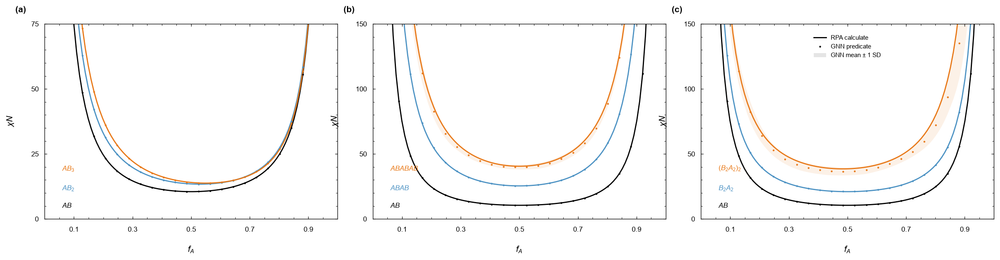

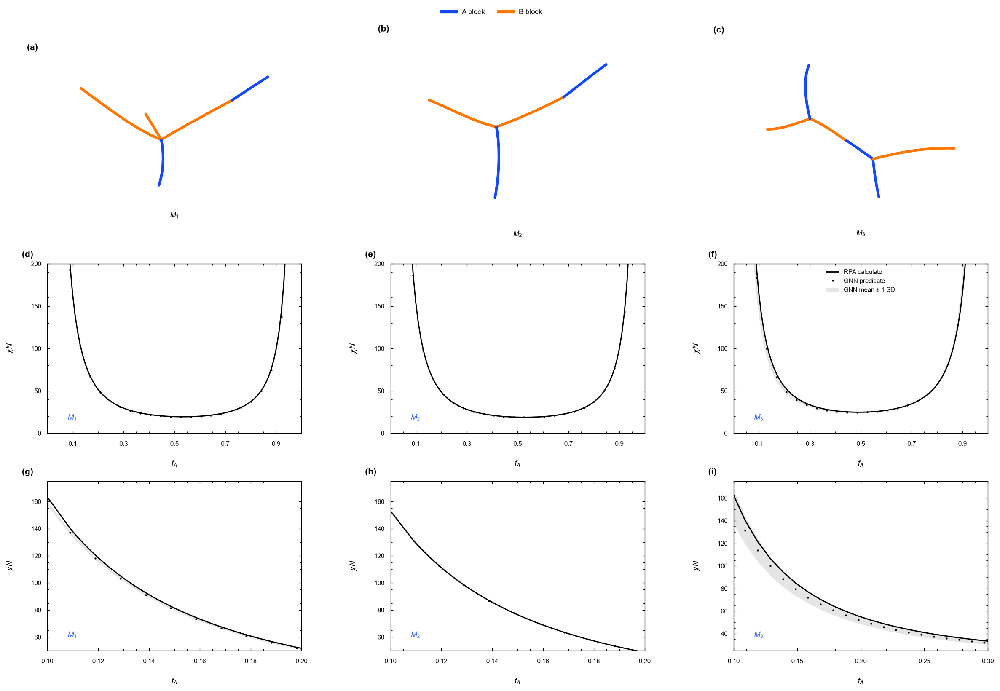

D:\2026\paper\TAPD\sourcecode\code\results\reproduced\composition_curves\figure6_stability_limit_dashboard
D:\2026\paper\TAPD\sourcecode\code\results\reproduced\composition_curves\figure8_literature_architectures_stability_limits


In [7]:
def _draw_main_fig7_8():
    from pathlib import Path
    import sys
    import numpy as np
    import pandas as pd
    import mpltex
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/plotting/paper_style.py').is_file()) / 'src/plotting'))
    from paper_style import COLORS, configure_paper_style, style_axis, save_dual
    configure_paper_style()
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    from IPython.display import display, Image
    ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'checkpoints/gnn').is_dir())
    DATA=ROOT/'results/source_data/composition_curves'
    OUT=ROOT/'results/reproduced/composition_curves'
    df=pd.read_csv(DATA/'five_seed_phase_diagram_predictions.csv')
    seed_columns=[f'seed_{s}' for s in range(202601,202606)]
    np.testing.assert_allclose(df[seed_columns].mean(axis=1),df.ml_mean,rtol=1e-10)
    np.testing.assert_allclose(df[seed_columns].std(axis=1,ddof=1),df.ml_std,rtol=1e-10)
    assert df.groupby(['case','topology']).size().eq(100).all()
    summary=[]
    for (case,topology),g in df.groupby(['case','topology']):
        summary.append(dict(case=case,topology=topology,n=len(g),fA_min=g.fA.min(),fA_max=g.fA.max(),MAPE=np.mean(abs(g.ml_mean-g.rpa_chiN)/g.rpa_chiN)*100,coverage=np.mean(abs(g.ml_mean-g.rpa_chiN)<=g.ml_std)*100))
    pd.DataFrame(summary).to_csv(DATA/'curve_metrics.csv',index=False)
    print(pd.DataFrame(summary).to_string(index=False))
    import json, math
    from matplotlib.path import Path as MplPath
    from matplotlib.patches import PathPatch
    FIGURE_DIR = OUT / 'panel_sources'
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    def save(fig, name):
        save_dual(fig, FIGURE_DIR / name)
        fig.savefig((FIGURE_DIR / name).with_suffix('.pdf'), dpi=600, bbox_inches='tight',pad_inches=.03)
        plt.close(fig)

    # Back-calculated from the final-size typography of main Fig. 6g-h.
    # Global panels: 51/42 pt -> approximately 6/5 pt after composition.
    # Local panels: 44/36 pt -> approximately 6/5 pt after composition.
    LEGEND_SIZE = 42

    AXIS_LABEL_SIZE = 51

    TICK_LABEL_SIZE = 42

    # Fig. 8 uses different global/local source canvases. These values make
    # both rows equal at final manuscript size: axis titles about 6.05 pt,
    # tick/legend text about 5 pt, and M1/M2/M3 annotations about 6.05 pt.
    FIG8_GLOBAL_AXIS_LABEL_SIZE = 53

    FIG8_GLOBAL_TICK_LABEL_SIZE = 44

    FIG8_GLOBAL_ANNOTATION_SIZE = 53

    LOCAL_AXIS_LABEL_SIZE = 44

    LOCAL_TICK_LABEL_SIZE = 36

    LOCAL_ANNOTATION_SIZE = 44

    # Shared spacing template for the stability-limit panels in main Figs. 7–8.
    X_TICK_PAD = 9
    Y_TICK_PAD = 7
    X_LABEL_PAD = 15
    Y_LABEL_PAD = 20

    # Author text directly in the journal font.  SVG export must not substitute
    # font families or reconstruct glyph positions after plotting.
    COMPOSITION_FONT_STYLE = {
        "font.family": "Arial",
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
    }
    plt.rcParams.update(COMPOSITION_FONT_STYLE)

    ML_MARKER_SIZE = 11

    TOPOLOGY_COLORS = {
        "AB": COLORS["blue"],
        "ABA": COLORS["orange"],
        "ABAB": COLORS["green"],
        "ABABA": COLORS["purple"],
        "AB2": COLORS["teal"],
        "AB3": COLORS["red"],
        "M1": COLORS["amber"],
        "M2": COLORS["teal"],
        "BTABAT": COLORS["density_green"],
        "B2A2": COLORS["mean_orange"],
        "(B2A2)2": COLORS["purple"],
    }

    LABELS = {
        "AB": r"$AB$", "ABA": r"$ABA$", "ABAB": r"$ABAB$", "ABABA": r"$ABABA$",
        "AB2": r"$AB_2$", "AB3": r"$AB_3$", "ABABAB": r"$ABABAB$",
        "M1": r"$M_1$", "M2": r"$M_2$",
        "BTABAT": r"$M_3$", "B2A2": r"$B_2A_2$", "(B2A2)2": r"$(B_2A_2)_2$",
    }

    def draw_series(
        ax, values: dict, topology: str, *, labeled: bool = True,
        marker_step: int = 4, color_override: str | None = None,
        band_alpha: float = 0.28,
    ) -> None:
        x = np.asarray(values["rpa"]["fA"])
        ml_x = np.asarray(values.get("ml_fA", values["rpa"]["fA"]))
        rpa = np.asarray(values["rpa"]["chiN"])
        mean = np.asarray(values["ml_mean"])
        std = np.asarray(values["ml_std"])
        band_x = np.asarray(values.get("band_fA", ml_x))
        band_mean = np.asarray(values.get("band_mean", mean))
        band_std = np.asarray(values.get("band_std", std))
        color = color_override or TOPOLOGY_COLORS[topology]
        prefix = f"{LABELS[topology]} " if labeled else ""
        ax.plot(x, rpa, color=color, lw=1.35, label=f"{prefix}RPA", zorder=2)
        ax.fill_between(band_x, np.maximum(band_mean - band_std, 0), band_mean + band_std,
                        color=color, alpha=band_alpha, linewidth=0, zorder=1)
        ax.plot(ml_x[::marker_step], mean[::marker_step], linestyle="none", marker="o", ms=ML_MARKER_SIZE,
                color=color, markeredgecolor="none", markeredgewidth=0,
                label=f"{prefix}GNN", zorder=3)

    def structure_label_size(ax) -> float:
        """Scale topology labels to match M1's 32 pt on a 5.8-inch panel."""
        spec = ax.get_subplotspec()
        rows = spec.get_gridspec().nrows if spec is not None else 1
        panel_height = ax.figure.get_figheight() / rows
        return 32.0 * panel_height / 5.8

    def add_standard_legend(ax) -> None:
        """Use one legend design and method ordering throughout the figure set."""
        handles, labels = ax.get_legend_handles_labels()
        # Matplotlib fills multi-column legends column-first.  Reorder the natural
        # topology-wise pairs so every visible row is ``RPA | GNN`` for the
        # same architecture.
        if len(handles) % 2 == 0:
            order = list(range(0, len(handles), 2)) + list(range(1, len(handles), 2))
            handles = [handles[index] for index in order]
            labels = [labels[index] for index in order]
        ax.legend(
            handles,
            labels,
            ncol=2,
            loc="upper center",
            fontsize=LEGEND_SIZE,
            frameon=False,
            handlelength=2.2,
            handletextpad=0.7,
            columnspacing=1.5,
            labelspacing=0.45,
            borderaxespad=0.55,
        )

    def finish_axis(
        ax,
        *,
        xlim=(0, 1),
        ylim=(0, 210),
        annotation: str | None = None,
        annotation_x: float = 0.08,
        axis_label_size: float = AXIS_LABEL_SIZE,
        tick_label_size: float = TICK_LABEL_SIZE,
    ) -> None:
        ax.set(xlim=xlim, ylim=ylim)
        # Use one Arial text run so χ and N have exactly the same family, size,
        # weight, and spacing.  MathText split the former label into STIX glyphs.
        ax.set_xlabel(r"$f_A$", labelpad=X_LABEL_PAD)
        ax.set_ylabel(
            "χN", labelpad=Y_LABEL_PAD,
            fontfamily="Arial", fontstyle="italic", fontweight="normal",
        )
        if xlim == (0, 1):
            ax.set_xticks([0.1, 0.3, 0.5, 0.7, 0.9])
        if ylim == (0, 210):
            ax.set_yticks([0, 50, 100, 150, 200])
        elif ylim == (0, 550):
            ax.set_yticks([0, 100, 200, 300, 400, 500])
        if annotation:
            # The lower-left branch of every U-shaped spinodal contains data.  Keep
            # the panel identifier in the open upper-left region instead.
            ax.text(annotation_x, 0.78, annotation, transform=ax.transAxes,
                    fontsize=structure_label_size(ax), fontstyle="italic")
        style_axis(ax)
        for spine in ax.spines.values():
            spine.set_linewidth(0.65)
        ax.tick_params(which="major", width=0.6, length=3.0)
        ax.tick_params(which="minor", width=0.45, length=1.8)
        # Keep both coordinate directions visually identical in every panel.
        ax.xaxis.label.set_fontsize(axis_label_size)
        ax.yaxis.label.set_fontsize(axis_label_size)
        ax.tick_params(axis="x", which="major", labelsize=tick_label_size, pad=X_TICK_PAD)
        ax.tick_params(axis="y", which="major", labelsize=tick_label_size, pad=Y_TICK_PAD)
    ML_MARKER_SIZE = 2.1
    payload = json.loads((DATA / "five_seed_phase_diagram_predictions.json").read_text(encoding="utf-8"))

    A_COLOR = "#1248ff"

    B_COLOR = "#ff7600"

    NODE_COLOR = "#ad5100"

    LINE_WIDTH = 3.0

    NODE_SIZE = 46

    LABEL_SIZE = 23

    LEGEND_SIZE = 27

    TITLE_SIZE = 25

    DRAW_SEGMENT_LABELS = False

    M1_FORMULA = r"$\mathrm{M}_1:\mathrm{A}_1(\mathrm{B}_1)\mathrm{T}(\mathrm{B}_3)\mathrm{T}\mathrm{B}_2\mathrm{A}_2$"

    M2_FORMULA = r"$\mathrm{M}_2:\mathrm{A}_1(\mathrm{B}_3)\mathrm{T}\mathrm{B}_2\mathrm{A}_2$"

    BTABAT_FORMULA = r"$\mathrm{A}_1(\mathrm{B}_1)_{\mathrm{T}}\mathrm{B}_2\mathrm{A}_2(\mathrm{A}_3)_{\mathrm{T}}\mathrm{B}_3$"

    BTABAT_FULL_FORMULA = (
        r"$\mathrm{M}_3:"
        r"\mathrm{A}_1(\mathrm{B}_1)_{\mathrm{T}}\mathrm{B}_2\mathrm{A}_2"
        r"(\mathrm{A}_3)_{\mathrm{T}}\mathrm{B}_3$"
    )

    def bezier(ax, p0, p1, p2, p3, color, label=None, label_t=0.5, label_offset=(0, 0), rotation=None):
        path = MplPath([p0, p1, p2, p3], [MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4])
        patch = PathPatch(path, facecolor="none", edgecolor=color, lw=LINE_WIDTH, capstyle="round", joinstyle="round")
        ax.add_patch(patch)
        if not DRAW_SEGMENT_LABELS:
            return
        if label:
            x, y = cubic_point(p0, p1, p2, p3, label_t)
            if rotation is None:
                dx, dy = cubic_tangent(p0, p1, p2, p3, label_t)
                rotation = math.degrees(math.atan2(dy, dx))
            ax.text(
                x + label_offset[0],
                y + label_offset[1],
                label,
                color=color,
                fontsize=LABEL_SIZE,
                ha="center",
                va="center",
                rotation=rotation,
                rotation_mode="anchor",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.72, "pad": 0.4},
            )

    def cubic_point(p0, p1, p2, p3, t):
        u = 1 - t
        x = u**3 * p0[0] + 3 * u**2 * t * p1[0] + 3 * u * t**2 * p2[0] + t**3 * p3[0]
        y = u**3 * p0[1] + 3 * u**2 * t * p1[1] + 3 * u * t**2 * p2[1] + t**3 * p3[1]
        return x, y

    def cubic_tangent(p0, p1, p2, p3, t):
        u = 1 - t
        dx = 3 * u**2 * (p1[0] - p0[0]) + 6 * u * t * (p2[0] - p1[0]) + 3 * t**2 * (p3[0] - p2[0])
        dy = 3 * u**2 * (p1[1] - p0[1]) + 6 * u * t * (p2[1] - p1[1]) + 3 * t**2 * (p3[1] - p2[1])
        return dx, dy

    def setup_figure():
        fig, ax = plt.subplots(figsize=(7.0, 5.2), dpi=222)
        ax.set_aspect("equal")
        ax.axis("off")
        return fig, ax

    def setup_axis(ax):
        ax.set_aspect("equal")
        ax.axis("off")

    def add_block_legend(
        ax, *, loc="lower center", bbox_to_anchor=(0.5, -0.18), ncols=2,
        fontsize=LEGEND_SIZE,
    ):
        handles = [
            Line2D([0], [0], color=A_COLOR, lw=LINE_WIDTH, label="A block"),
            Line2D([0], [0], color=B_COLOR, lw=LINE_WIDTH, label="B block"),
        ]
        ax.legend(
            handles=handles,
            loc=loc,
            bbox_to_anchor=bbox_to_anchor,
            ncols=ncols,
            frameon=False,
            fontsize=fontsize,
            handlelength=2.4,
            columnspacing=3.0,
            handletextpad=0.8,
        )

    def finish(fig, ax, path, include_legend=False, legend_kwargs=None):
        if include_legend:
            add_block_legend(ax, **(legend_kwargs or {}))
        ax.margins(0.10)
        fig.savefig(path, dpi=222, transparent=False, facecolor="white", bbox_inches="tight", pad_inches=0.15)
        fig.savefig(path.with_suffix(".svg"), transparent=False, facecolor="white",
                    bbox_inches="tight", pad_inches=0.15)
        plt.close(fig)
        print(f"Saved {path}")

    def nodes(ax, pts):
        xs = [p[0] for p in pts]
        ys = [p[1] for p in pts]
        ax.scatter(xs, ys, s=NODE_SIZE, color=NODE_COLOR, zorder=5, edgecolors="none")

    def architecture_title(ax, text, fontsize=TITLE_SIZE):
        ax.text(
            0.5,
            1.03,
            text,
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=fontsize,
            fontfamily="STIXGeneral",
            color="black",
        )

    def figure_title(fig, x, y, text):
        fig.text(
            x,
            y,
            text,
            ha="left",
            va="top",
            fontsize=TITLE_SIZE,
            fontfamily="STIXGeneral",
            color="black",
        )

    def draw_m1_architecture(ax, *, show_nodes=True):
        c = (0.0, 0.0)
        b1_end = (-0.26, 0.43)
        b2_end = (1.18, 0.66)
        b3_end = (-1.34, 0.86)
        a2_end = (1.78, 1.05)
        a1_end = (-0.04, -0.76)

        bezier(ax, c, (-0.44, 0.18), (-0.88, 0.52), b3_end, B_COLOR, "B3", 0.55, (0.00, 0.12), -23)
        bezier(ax, c, (-0.08, 0.14), (-0.17, 0.29), b1_end, B_COLOR, "B1", 0.53, (-0.12, 0.04), -60)
        bezier(ax, c, (0.34, 0.21), (0.78, 0.44), b2_end, B_COLOR, "B2", 0.58, (0.02, 0.13), 38)
        bezier(ax, b2_end, (1.40, 0.80), (1.60, 0.94), a2_end, A_COLOR, "A2", 0.50, (0.00, 0.13), 25)
        bezier(ax, c, (0.05, -0.22), (0.04, -0.54), a1_end, A_COLOR, "A1", 0.55, (0.13, 0.00), 83)
        if show_nodes:
            nodes(ax, [c, b1_end, b2_end, b3_end, a2_end, a1_end])

    def draw_m2_architecture(ax, *, show_nodes=True):
        c = (0.0, 0.0)
        b1_end = (-0.95, 0.38)
        b2_end = (0.95, 0.42)
        a2_end = (1.55, 0.88)
        a1_end = (-0.02, -1.00)

        bezier(ax, c, (-0.25, 0.05), (-0.58, 0.22), b1_end, B_COLOR, "B1", 0.50, (-0.02, 0.11), -25)
        bezier(ax, c, (0.28, 0.10), (0.62, 0.25), b2_end, B_COLOR, "B2", 0.54, (0.02, 0.13), 28)
        bezier(ax, b2_end, (1.16, 0.58), (1.38, 0.76), a2_end, A_COLOR, "A2", 0.54, (0.00, 0.13), 32)
        bezier(ax, c, (0.06, -0.30), (0.04, -0.70), a1_end, A_COLOR, "A1", 0.55, (0.13, 0.00), 86)
        if show_nodes:
            nodes(ax, [c, b1_end, b2_end, a2_end, a1_end])

    def draw_btabat_architecture(ax):
        t_a = (-0.58, 0.40)
        ab = (0.00, 0.05)
        t_b = (0.48, -0.28)
        a1_end = (0.58, -0.92)
        a3_end = (-0.60, 1.30)
        b2_end = (-1.30, 0.22)
        b3_end = (1.85, -0.10)

        bezier(ax, t_b, (0.50, -0.50), (0.54, -0.75), a1_end, A_COLOR, "A1", 0.58, (0.13, 0.00), 82)
        bezier(ax, t_b, (0.28, -0.14), (0.12, -0.02), ab, A_COLOR, "A2", 0.54, (-0.08, -0.11), -54)
        bezier(ax, ab, (-0.16, 0.16), (-0.35, 0.30), t_a, B_COLOR, "B1", 0.54, (0.07, 0.10), 41)
        bezier(ax, t_a, (-0.86, 0.30), (-1.08, 0.22), b2_end, B_COLOR, "B2", 0.54, (0.00, 0.12), 12)
        bezier(ax, t_a, (-0.66, 0.70), (-0.70, 1.06), a3_end, A_COLOR, "A3", 0.50, (-0.13, 0.00), 87)
        bezier(ax, t_b, (0.88, -0.18), (1.34, -0.08), b3_end, B_COLOR, "B3", 0.56, (0.00, 0.13), 6)

    # Main Figs. 7 and 8: every curve and architecture is drawn directly from
    # the bundled numerical JSON. No existing PNG/SVG/PDF is read or embedded.
    from matplotlib.patches import Patch

    def draw_comparison(ax, data, topologies, ymax, *, shared_legend=False):
        palette = [plt.rcParams["axes.labelcolor"], COLORS["blue"], COLORS["orange"]]
        handles = []
        for topology, color in zip(topologies, palette):
            draw_series(ax, data[topology], topology, labeled=False,
                        color_override=color, band_alpha=.10)
            if not handles:
                handles = ax.get_legend_handles_labels()[0][-2:]
            # Each architecture's identity remains next to its curve family.
        finish_axis(ax, ylim=(0, ymax), axis_label_size=9.5, tick_label_size=8)
        ax.set_yticks([0, 25, 50, 75] if ymax == 75 else [0, 50, 100, 150])
        for topology, y, color in zip(topologies, [.05, .14, .24], palette):
            ax.text(.06, y, LABELS[topology], transform=ax.transAxes,
                    ha="left", va="bottom", fontsize=8, fontstyle="italic", color=color)
        if shared_legend:
            handles.append(Patch(facecolor=palette[0], alpha=.10, edgecolor="none"))
            ax.legend(handles, ["RPA calculate", "GNN predicate", r"GNN mean $\pm$ 1 SD"],
                      loc="upper center", bbox_to_anchor=(.5, .97), frameon=False, fontsize=7)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.06), facecolor="white")
    for ax, group, ymax, label in zip(axes,
        [("AB", "AB2", "AB3"), ("AB", "ABAB", "ABABAB"), ("AB", "B2A2", "(B2A2)2")],
        [75, 150, 150], "abc"):
        data = payload["cases"]["shi"] if label == "c" else payload["cases"]["global"]
        draw_comparison(ax, data, group, ymax, shared_legend=(label == "c"))
        ax.set_box_aspect(2/3)
        ax.text(-.10, 1.06, f"({label})", transform=ax.transAxes,
                fontsize=10, fontweight="bold", clip_on=False)
    fig.subplots_adjust(left=.035, right=.995, bottom=.12, top=.94, wspace=.12)
    output7 = ROOT / "results/reproduced/composition_curves/figure6_stability_limit_dashboard"
    output7.parent.mkdir(parents=True, exist_ok=True)
    save_dual(fig, output7, tight=False)
    fig.savefig(output7.with_suffix(".pdf"), facecolor="white")
    display(fig)
    plt.close(fig)

    def local_curve(data, topology):
        values = data["global"][topology] if topology != "BTABAT" else data["btabat"][topology]
        x = np.asarray(values["rpa"]["fA"], dtype=float)
        if topology in ("M1", "M2"):
            local_rpa = data["m1_m2_local"][topology]["rpa"]
            local_x = np.asarray(local_rpa["fA"], dtype=float)
            local_y = np.asarray(local_rpa["chiN"], dtype=float)
            context = (x >= .08) & (x <= .22)
            selected = (x >= .10) & (x <= .20)
            rpa_x = np.r_[x[context], local_x]
            rpa_y = np.r_[np.asarray(values["rpa"]["chiN"])[context], local_y]
            order = np.argsort(rpa_x)
            return {"rpa": {"fA": rpa_x[order], "chiN": rpa_y[order]},
                    "ml_fA": x[selected], "ml_mean": np.asarray(values["ml_mean"])[selected],
                    "ml_std": np.asarray(values["ml_std"])[selected],
                    "band_fA": x[context], "band_mean": np.asarray(values["ml_mean"])[context],
                    "band_std": np.asarray(values["ml_std"])[context]}
        selected = (x > .10) & (x < .30)
        lo = max(int(np.searchsorted(x, .10, side="left"))-1, 0)
        hi = min(int(np.searchsorted(x, .30, side="right"))+1, len(x))
        context = slice(lo, hi)
        return {"rpa": {"fA": x[context], "chiN": np.asarray(values["rpa"]["chiN"])[context]},
                "ml_fA": x[selected], "ml_mean": np.asarray(values["ml_mean"])[selected],
                "ml_std": np.asarray(values["ml_std"])[selected],
                "band_fA": x[context], "band_mean": np.asarray(values["ml_mean"])[context],
                "band_std": np.asarray(values["ml_std"])[context]}

    fig, axes = plt.subplots(3, 3, figsize=(16, 10.89), facecolor="white")
    arch_drawers = (draw_m1_architecture, draw_m2_architecture, draw_btabat_architecture)
    for col, (ax, drawer, title) in enumerate(zip(axes[0], arch_drawers,
                                                  (r"$M_1$", r"$M_2$", r"$M_3$"))):
        setup_axis(ax)
        if col < 2:
            drawer(ax, show_nodes=False)
        else:
            drawer(ax)
        ax.margins(.18)
        ax.text(.5, -.05, title, transform=ax.transAxes, ha="center", va="top",
                fontsize=8, clip_on=False)
        ax.text(-.08, 1.05, f"({chr(97+col)})", transform=ax.transAxes,
                fontsize=10, fontweight="bold", clip_on=False)
    fig.legend(handles=[Line2D([0], [0], color=A_COLOR, lw=4, label="A block"),
                        Line2D([0], [0], color=B_COLOR, lw=4, label="B block")],
               loc="upper center", bbox_to_anchor=(.5, 1.005), ncol=2,
               frameon=False, fontsize=8)
    for col, topology in enumerate(("M1", "M2", "BTABAT")):
        values = payload["cases"]["btabat"][topology] if col == 2 else payload["cases"]["global"][topology]
        for row in (1, 2):
            ax = axes[row, col]
            local = row == 2
            series = local_curve(payload["cases"], topology) if local else values
            draw_series(ax, series, topology, labeled=False, marker_step=1 if local else 4,
                        color_override=plt.rcParams["axes.labelcolor"], band_alpha=.10)
            finish_axis(ax, xlim=(.10, .30 if col == 2 else .20) if local else (0, 1),
                        ylim=(25, 175) if local and col == 2 else ((50, 175) if local else (0, 200)),
                        axis_label_size=8.5, tick_label_size=7)
            ax.set_box_aspect(2/3)
            ax.text(.08, .08, LABELS[topology], transform=ax.transAxes,
                    fontsize=8.5, fontstyle="italic", color="#3568F4")
            if local:
                ax.set_xticks([.10, .15, .20, .25, .30] if col == 2
                              else [.10, .12, .14, .16, .18, .20])
            else:
                ax.set_yticks([0, 50, 100, 150, 200])
            ax.text(-.10, 1.04, f"({chr(100 + (row-1)*3 + col)})",
                    transform=ax.transAxes, fontsize=10, fontweight="bold", clip_on=False)
            if row == 1 and col == 2:
                h = ax.get_legend_handles_labels()[0]
                h.append(Patch(facecolor=plt.rcParams["axes.labelcolor"], alpha=.10, edgecolor="none"))
                ax.legend(h, ["RPA calculate", "GNN predicate", r"GNN mean $\pm$ 1 SD"],
                          loc="upper center", fontsize=7, frameon=False)
    fig.subplots_adjust(left=.06, right=.99, bottom=.055, top=.95, wspace=.35, hspace=.20)
    output8 = ROOT / "results/reproduced/composition_curves/figure8_literature_architectures_stability_limits"
    save_dual(fig, output8, tight=False)
    fig.savefig(output8.with_suffix(".pdf"), facecolor="white")
    display(fig)
    plt.close(fig)
    print(output7, output8, sep="\n")

_draw_main_fig7_8()


## Fig. 9 — GINE encoder schematic


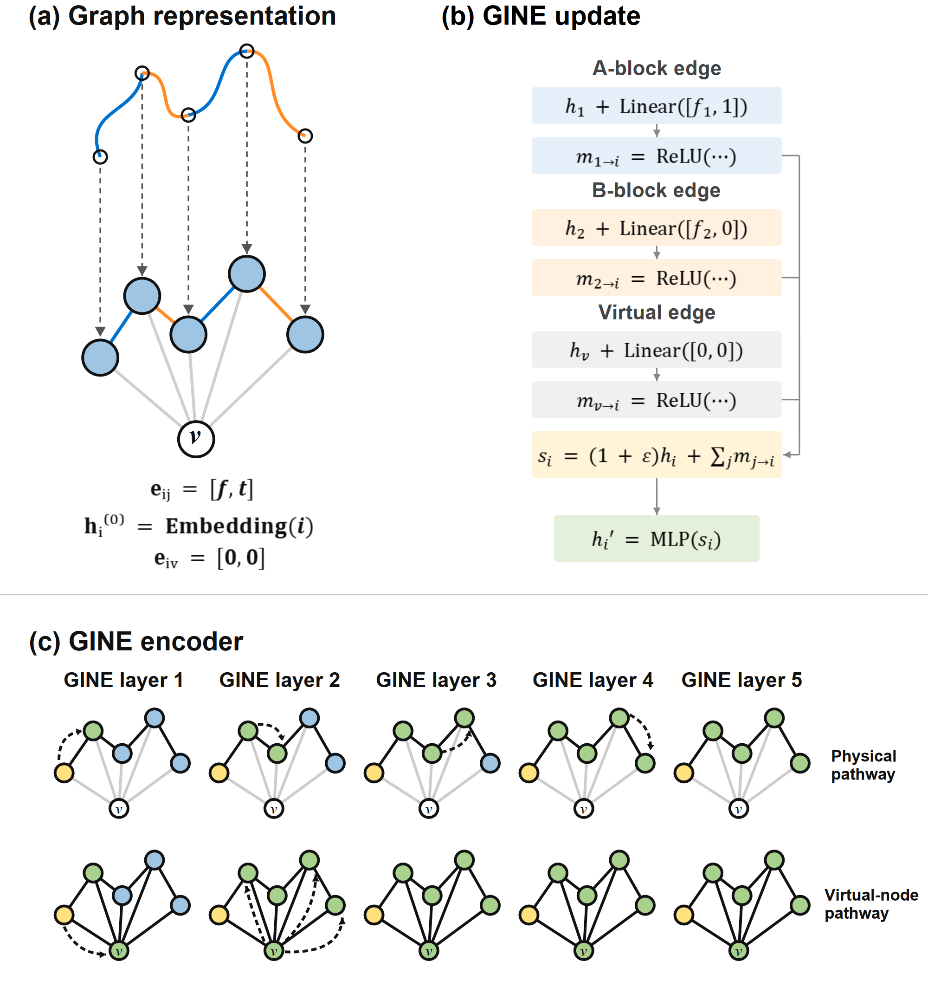

In [8]:
display(Image(filename=str(CODE / "results" / "figures" / "gine_ppt_vector" / "figure9_gine_encoder.png"), width=850))
